In [1]:
# #step 1 - Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

print("Libraries imported successfully!")
print("NumPy version:", np.__version__)

Libraries imported successfully!
NumPy version: 2.1.3


In [2]:
# #step 2 - Create a small dataset for gradient descent experiments

X = np.array([1, 2, 3, 4, 5], dtype=float).reshape(-1, 1)

y = np.array([5, 8, 11, 14, 17], dtype=float).reshape(-1, 1)

print("Input data:")
print(X.flatten())

print("\nTarget values:")
print(y.flatten())

print("\nDataset shape:", X.shape)

Input data:
[1. 2. 3. 4. 5.]

Target values:
[ 5.  8. 11. 14. 17.]

Dataset shape: (5, 1)


In [3]:
# #step 3 - Implement Batch Gradient Descent

def batch_gradient_descent(X, y, learning_rate=0.01, epochs=100):

    m = len(X)

    weight = 0.0
    bias = 0.0

    loss_history = []

    for epoch in range(epochs):

        # Forward propagation
        predictions = weight * X + bias

        # Calculate error
        error = predictions - y

        # Mean squared error
        loss = np.mean(error ** 2)

        # Calculate gradients using entire dataset
        dw = (2 / m) * np.sum(error * X)
        db = (2 / m) * np.sum(error)

        # Update parameters
        weight -= learning_rate * dw
        bias -= learning_rate * db

        loss_history.append(loss)

    return weight, bias, loss_history


batch_w, batch_b, batch_loss = batch_gradient_descent(
    X, y,
    learning_rate=0.01,
    epochs=100
)

print("Batch Gradient Descent")
print("Weight:", batch_w)
print("Bias:", batch_b)
print("Final loss:", batch_loss[-1])

Batch Gradient Descent
Weight: 3.2143394364429017
Bias: 1.2261666248821057
Final loss: 0.10973614256204316


In [4]:
# #step 4 - Implement Stochastic Gradient Descent

def stochastic_gradient_descent(
    X, y, learning_rate=0.01, epochs=100
):

    weight = 0.0
    bias = 0.0

    loss_history = []

    m = len(X)

    for epoch in range(epochs):

        # Shuffle the training examples
        indices = np.random.permutation(m)

        for i in indices:

            xi = X[i:i+1]
            yi = y[i:i+1]

            # Prediction
            prediction = weight * xi + bias

            error = prediction - yi

            # Gradients from one sample
            dw = 2 * error[0, 0] * xi[0, 0]
            db = 2 * error[0, 0]

            # Update weights
            weight -= learning_rate * dw
            bias -= learning_rate * db

        # Calculate loss over entire dataset
        predictions = weight * X + bias
        loss = np.mean((predictions - y) ** 2)

        loss_history.append(loss)

    return weight, bias, loss_history


sgd_w, sgd_b, sgd_loss = stochastic_gradient_descent(
    X, y,
    learning_rate=0.01,
    epochs=100
)

print("Stochastic Gradient Descent")
print("Weight:", sgd_w)
print("Bias:", sgd_b)
print("Final loss:", sgd_loss[-1])

Stochastic Gradient Descent
Weight: 3.0454289302016955
Bias: 1.8137063202069388
Final loss: 0.0066282643647994095


In [5]:
# #step 5 - Implement Mini-batch Gradient Descent

def mini_batch_gradient_descent(
    X, y, learning_rate=0.01, epochs=100, batch_size=2
):

    m = len(X)

    weight = 0.0
    bias = 0.0

    loss_history = []

    for epoch in range(epochs):

        # Shuffle dataset
        indices = np.random.permutation(m)

        X_shuffled = X[indices]
        y_shuffled = y[indices]

        # Process mini-batches
        for start in range(0, m, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            batch_count = len(X_batch)

            # Predictions
            predictions = weight * X_batch + bias

            error = predictions - y_batch

            # Gradients
            dw = (2 / batch_count) * np.sum(error * X_batch)
            db = (2 / batch_count) * np.sum(error)

            # Update parameters
            weight -= learning_rate * dw
            bias -= learning_rate * db

        # Calculate full dataset loss
        predictions = weight * X + bias
        loss = np.mean((predictions - y) ** 2)

        loss_history.append(loss)

    return weight, bias, loss_history


mini_w, mini_b, mini_loss = mini_batch_gradient_descent(
    X, y,
    learning_rate=0.01,
    epochs=100,
    batch_size=2
)

print("Mini-batch Gradient Descent")
print("Weight:", mini_w)
print("Bias:", mini_b)
print("Final loss:", mini_loss[-1])

Mini-batch Gradient Descent
Weight: 3.1086133905232742
Bias: 1.6224543324852454
Final loss: 0.02626719551283376


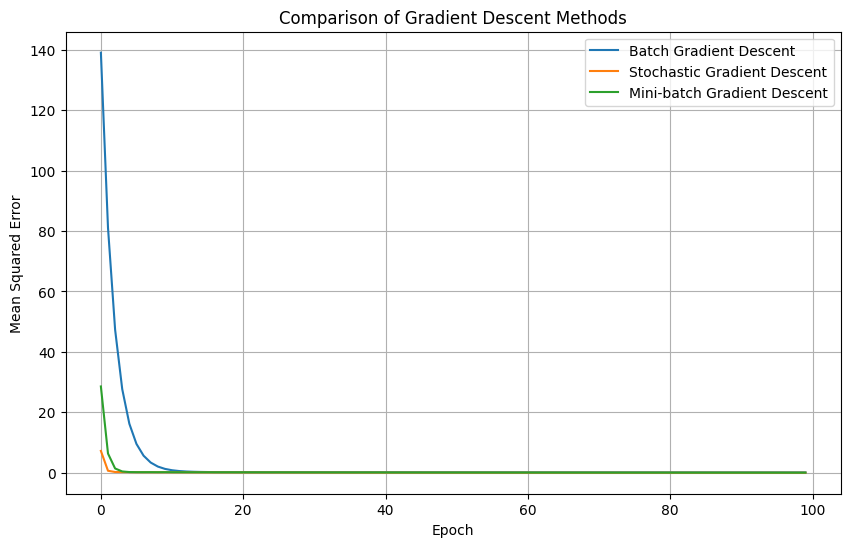

In [6]:
# #step 6 - Compare Batch, Stochastic and Mini-batch Gradient Descent

plt.figure(figsize=(10, 6))

plt.plot(batch_loss, label="Batch Gradient Descent")
plt.plot(sgd_loss, label="Stochastic Gradient Descent")
plt.plot(mini_loss, label="Mini-batch Gradient Descent")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Comparison of Gradient Descent Methods")

plt.legend()
plt.grid(True)
plt.show()

In [7]:
# #step 6 - Display gradient descent performance comparison

comparison_df = pd.DataFrame({
    "Method": [
        "Batch Gradient Descent",
        "Stochastic Gradient Descent",
        "Mini-batch Gradient Descent"
    ],

    "Final Weight": [
        batch_w,
        sgd_w,
        mini_w
    ],

    "Final Bias": [
        batch_b,
        sgd_b,
        mini_b
    ],

    "Final Loss": [
        batch_loss[-1],
        sgd_loss[-1],
        mini_loss[-1]
    ]
})

print(comparison_df.round(6).to_string(index=False))

                     Method  Final Weight  Final Bias  Final Loss
     Batch Gradient Descent      3.214339    1.226167    0.109736
Stochastic Gradient Descent      3.045429    1.813706    0.006628
Mini-batch Gradient Descent      3.108613    1.622454    0.026267


## Conclusion – Comparison of Gradient Descent Methods

1. Batch, Stochastic and Mini-batch Gradient Descent were implemented using NumPy on a small linear regression dataset.

2. Batch Gradient Descent calculates gradients using the entire dataset and updates the model parameters once per epoch. It showed smooth convergence but achieved a final loss of 0.1097.

3. Stochastic Gradient Descent updates the model parameters using one training example at a time. It achieved the lowest final loss of 0.0066 and estimated the weight and bias closest to their actual values.

4. Mini-batch Gradient Descent updates parameters using smaller groups of training examples. It achieved a final loss of 0.0263, providing performance between Batch and Stochastic Gradient Descent in this experiment.

5. The loss curves demonstrate that all three methods successfully reduced the prediction error and learned the underlying linear relationship.

6. The experiment shows that different gradient descent methods have different convergence behaviours. Batch Gradient Descent provides stable updates, Stochastic Gradient Descent allows frequent updates, and Mini-batch Gradient Descent combines the advantages of both approaches.

**Overall**, the choice of gradient descent method influences training speed, convergence behaviour and optimization performance.

In [8]:
# #step 7 - Load Fashion-MNIST dataset

from tensorflow.keras.datasets import fashion_mnist

(X_train_full, y_train_full), (X_test_full, y_test_full) = fashion_mnist.load_data()

print("Training dataset shape:", X_train_full.shape)
print("Testing dataset shape:", X_test_full.shape)

print("Number of classes:", len(np.unique(y_train_full)))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training dataset shape: (60000, 28, 28)
Testing dataset shape: (10000, 28, 28)
Number of classes: 10


We'll use:
- 8,000 training images.
- 2,000 testing images.
- 784 input features per image after flattening.
- Normalized pixel values between 0 and 1.

In [9]:
# #step 8 - Select subset and preprocess Fashion-MNIST

# Select training and testing subsets
X_train = X_train_full[:8000]
y_train = y_train_full[:8000]

X_test = X_test_full[:2000]
y_test = y_test_full[:2000]

# Flatten 28x28 images into 784 features
X_train = X_train.reshape(8000, 784)
X_test = X_test.reshape(2000, 784)

# Normalize pixel values
X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Training data shape: (8000, 784)
Testing data shape: (2000, 784)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


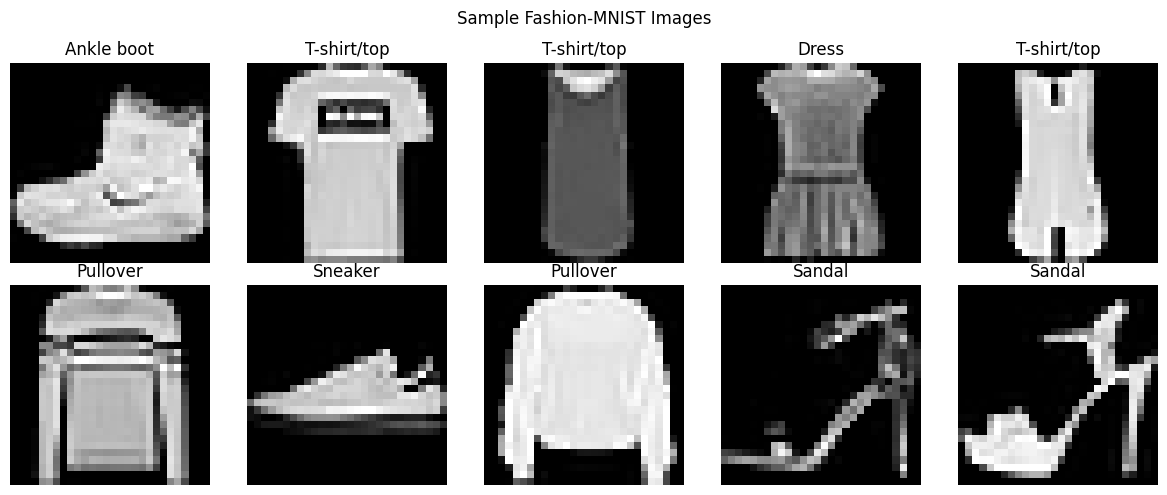

In [10]:
# #step 9 - Visualize sample Fashion-MNIST images

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train_full[i], cmap="gray")

    plt.title(class_names[y_train_full[i]])
    plt.axis("off")

plt.suptitle("Sample Fashion-MNIST Images")
plt.tight_layout()
plt.show()

### Observation – Fashion-MNIST Dataset Preparation

1. The Fashion-MNIST dataset was successfully loaded, containing 70,000 grayscale clothing images divided into 10 categories.

2. A subset of 8,000 images was selected for training and 2,000 images for testing to reduce computational requirements.

3. Each image was originally 28 × 28 pixels and was flattened into a 784-dimensional feature vector.

4. Pixel values were normalized from the original range of 0–255 to 0–1, making the data suitable for neural network training.

5. The sample visualization confirms that the dataset contains different clothing categories, such as T-shirts, trousers, dresses, sandals and sneakers.

**Overall**, the dataset was successfully prepared for comparing different optimization algorithms and training neural networks.

We'll compare four optimizers:
1. SGD – Standard gradient descent.
2. Momentum – Uses previous gradients to accelerate updates.
3. RMSProp – Adapts the learning rate using squared gradients.
4. Adam – Combines Momentum and RMSProp

In [11]:
# #step 10 - Implement SGD, Momentum, RMSProp and Adam optimizers

class Optimizer:

    def __init__(self, method, learning_rate=0.001,
                 beta1=0.9, beta2=0.999, epsilon=1e-8):

        self.method = method
        self.lr = learning_rate
        self.beta1 = beta1
        self.beta2 = beta2
        self.epsilon = epsilon

        self.m = {}
        self.v = {}
        self.t = 0

    def update(self, params, grads):

        self.t += 1

        for key in params:

            if self.method == "sgd":

                params[key] -= self.lr * grads[key]

            elif self.method == "momentum":

                if key not in self.m:
                    self.m[key] = np.zeros_like(params[key])

                self.m[key] = (
                    self.beta1 * self.m[key] +
                    (1 - self.beta1) * grads[key]
                )

                params[key] -= self.lr * self.m[key]

            elif self.method == "rmsprop":

                if key not in self.v:
                    self.v[key] = np.zeros_like(params[key])

                self.v[key] = (
                    self.beta2 * self.v[key] +
                    (1 - self.beta2) * grads[key] ** 2
                )

                params[key] -= (
                    self.lr * grads[key] /
                    (np.sqrt(self.v[key]) + self.epsilon)
                )

            elif self.method == "adam":

                if key not in self.m:
                    self.m[key] = np.zeros_like(params[key])
                    self.v[key] = np.zeros_like(params[key])

                self.m[key] = (
                    self.beta1 * self.m[key] +
                    (1 - self.beta1) * grads[key]
                )

                self.v[key] = (
                    self.beta2 * self.v[key] +
                    (1 - self.beta2) * grads[key] ** 2
                )

                m_hat = self.m[key] / (1 - self.beta1 ** self.t)
                v_hat = self.v[key] / (1 - self.beta2 ** self.t)

                params[key] -= (
                    self.lr * m_hat /
                    (np.sqrt(v_hat) + self.epsilon)
                )

            else:
                raise ValueError("Unknown optimizer")

        return params


print("SGD, Momentum, RMSProp and Adam implemented successfully!")

SGD, Momentum, RMSProp and Adam implemented successfully!


We'll use the following architecture:
- Input layer: 784 neurons
- Hidden layer 1: 128 neurons (ReLU)
- Hidden layer 2: 64 neurons (ReLU)
- Output layer: 10 neurons (Softmax)

In [12]:
# #step 11 - Implement MLP supporting different optimizers

def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)


class OptimizedMLP:

    def __init__(self, input_size=784, hidden1=128,
                 hidden2=64, output_size=10):

        # He initialization for ReLU layers
        self.params = {
            "W1": np.random.randn(input_size, hidden1) * np.sqrt(2 / input_size),
            "b1": np.zeros((1, hidden1)),

            "W2": np.random.randn(hidden1, hidden2) * np.sqrt(2 / hidden1),
            "b2": np.zeros((1, hidden2)),

            "W3": np.random.randn(hidden2, output_size) * np.sqrt(2 / hidden2),
            "b3": np.zeros((1, output_size))
        }

    def forward(self, X):

        self.z1 = X @ self.params["W1"] + self.params["b1"]
        self.a1 = np.maximum(0, self.z1)

        self.z2 = self.a1 @ self.params["W2"] + self.params["b2"]
        self.a2 = np.maximum(0, self.z2)

        self.z3 = self.a2 @ self.params["W3"] + self.params["b3"]
        self.a3 = softmax(self.z3)

        return self.a3

    def backward(self, X, y):

        m = X.shape[0]

        # Output layer gradients
        dz3 = (self.a3 - y) / m

        dW3 = self.a2.T @ dz3
        db3 = np.sum(dz3, axis=0, keepdims=True)

        # Second hidden layer gradients
        dz2 = (dz3 @ self.params["W3"].T) * (self.z2 > 0)

        dW2 = self.a1.T @ dz2
        db2 = np.sum(dz2, axis=0, keepdims=True)

        # First hidden layer gradients
        dz1 = (dz2 @ self.params["W2"].T) * (self.z1 > 0)

        dW1 = X.T @ dz1
        db1 = np.sum(dz1, axis=0, keepdims=True)

        grads = {
            "W1": dW1,
            "b1": db1,
            "W2": dW2,
            "b2": db2,
            "W3": dW3,
            "b3": db3
        }

        return grads

    def predict(self, X):

        probabilities = self.forward(X)

        return np.argmax(probabilities, axis=1)


print("Optimized MLP implemented successfully!")

Optimized MLP implemented successfully!


In [13]:
# #step 12 - Create training function for optimizer comparison

def train_optimizer_model(
    model, optimizer, X_train, y_train, X_test, y_test,
    epochs=8, batch_size=128, schedule=False
):

    y_train_onehot = np.eye(10)[y_train]

    history = {
        "loss": [],
        "train_accuracy": [],
        "test_accuracy": [],
        "learning_rate": []
    }

    for epoch in range(epochs):

        # Apply learning-rate scheduling if enabled
        if schedule:
            optimizer.lr = 0.001 * (0.9 ** epoch)

        history["learning_rate"].append(optimizer.lr)

        # Shuffle training data
        indices = np.random.permutation(len(X_train))

        X_shuffled = X_train[indices]
        y_shuffled = y_train_onehot[indices]

        for start in range(0, len(X_train), batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            # Forward propagation
            predictions = model.forward(X_batch)

            # Backpropagation
            grads = model.backward(X_batch, y_batch)

            # Optimizer update
            optimizer.update(model.params, grads)

        # Evaluate training data
        train_prob = model.forward(X_train)

        train_loss = -np.mean(
            np.log(
                np.clip(
                    train_prob[np.arange(len(y_train)), y_train],
                    1e-12, 1.0
                )
            )
        )

        train_accuracy = np.mean(
            np.argmax(train_prob, axis=1) == y_train
        )

        # Evaluate test data
        test_predictions = model.predict(X_test)

        test_accuracy = np.mean(test_predictions == y_test)

        history["loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["test_accuracy"].append(test_accuracy)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Loss: {train_loss:.4f} | "
            f"Train Accuracy: {train_accuracy * 100:.2f}% | "
            f"Test Accuracy: {test_accuracy * 100:.2f}% | "
            f"LR: {optimizer.lr:.6f}"
        )

    return history


print("Training and evaluation function ready!")

Training and evaluation function ready!


In [14]:
# #step 13 - Compare SGD, Momentum, RMSProp and Adam

optimizer_names = ["sgd", "momentum", "rmsprop", "adam"]

optimizer_results = {}

for method in optimizer_names:

    print("\nTraining using:", method.upper())
    print("=" * 50)

    np.random.seed(42)

    model = OptimizedMLP()

    optimizer = Optimizer(
        method=method,
        learning_rate=0.001
    )

    history = train_optimizer_model(
        model,
        optimizer,
        X_train,
        y_train,
        X_test,
        y_test,
        epochs=8,
        batch_size=128,
        schedule=False
    )

    optimizer_results[method] = history


print("\nAll optimizer experiments completed!")


Training using: SGD
Epoch 1/8 | Loss: 2.2195 | Train Accuracy: 19.07% | Test Accuracy: 19.15% | LR: 0.001000
Epoch 2/8 | Loss: 2.0690 | Train Accuracy: 26.81% | Test Accuracy: 27.40% | LR: 0.001000
Epoch 3/8 | Loss: 1.9499 | Train Accuracy: 34.67% | Test Accuracy: 35.35% | LR: 0.001000
Epoch 4/8 | Loss: 1.8454 | Train Accuracy: 43.64% | Test Accuracy: 45.00% | LR: 0.001000
Epoch 5/8 | Loss: 1.7511 | Train Accuracy: 50.85% | Test Accuracy: 50.40% | LR: 0.001000
Epoch 6/8 | Loss: 1.6662 | Train Accuracy: 55.75% | Test Accuracy: 54.95% | LR: 0.001000
Epoch 7/8 | Loss: 1.5904 | Train Accuracy: 59.38% | Test Accuracy: 59.15% | LR: 0.001000
Epoch 8/8 | Loss: 1.5222 | Train Accuracy: 61.46% | Test Accuracy: 60.40% | LR: 0.001000

Training using: MOMENTUM
Epoch 1/8 | Loss: 2.2430 | Train Accuracy: 18.15% | Test Accuracy: 18.45% | LR: 0.001000
Epoch 2/8 | Loss: 2.0860 | Train Accuracy: 25.97% | Test Accuracy: 26.55% | LR: 0.001000
Epoch 3/8 | Loss: 1.9659 | Train Accuracy: 33.51% | Test Accura

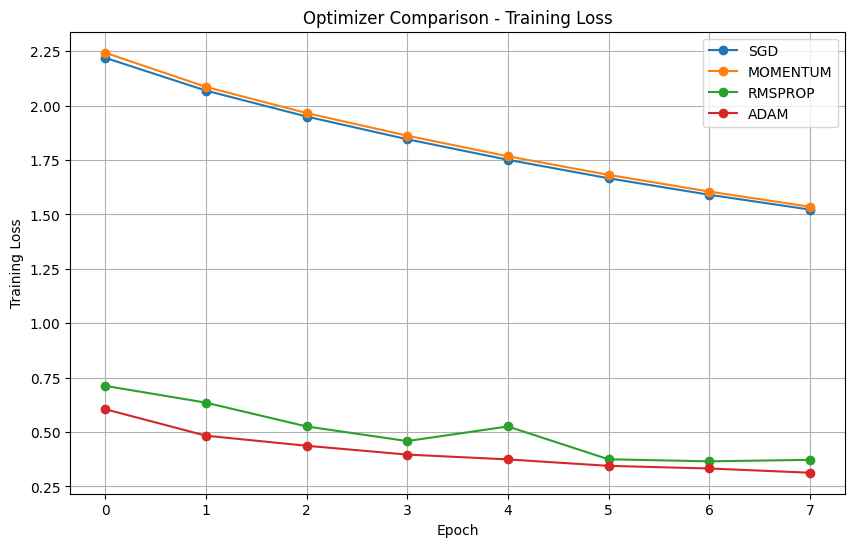

In [15]:
# #step 14 - Plot training loss comparison for all optimizers

plt.figure(figsize=(10, 6))

for method, history in optimizer_results.items():

    plt.plot(
        history["loss"],
        marker="o",
        label=method.upper()
    )

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Optimizer Comparison - Training Loss")

plt.legend()
plt.grid(True)
plt.show()

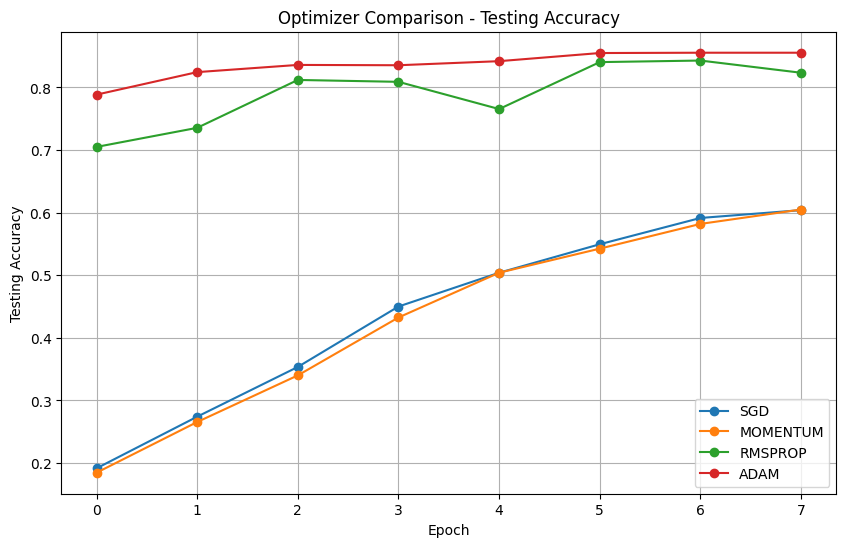

In [16]:
# #step 14 - Compare testing accuracy of different optimizers

plt.figure(figsize=(10, 6))

for method, history in optimizer_results.items():

    plt.plot(
        history["test_accuracy"],
        marker="o",
        label=method.upper()
    )

plt.xlabel("Epoch")
plt.ylabel("Testing Accuracy")
plt.title("Optimizer Comparison - Testing Accuracy")

plt.legend()
plt.grid(True)
plt.show()

In [17]:
# #step 14 - Create optimizer performance comparison table

optimizer_comparison = pd.DataFrame([

    {
        "Optimizer": method.upper(),
        "Final Training Loss": history["loss"][-1],
        "Training Accuracy (%)": history["train_accuracy"][-1] * 100,
        "Testing Accuracy (%)": history["test_accuracy"][-1] * 100
    }

    for method, history in optimizer_results.items()

])

print(optimizer_comparison.round(4).to_string(index=False))

Optimizer  Final Training Loss  Training Accuracy (%)  Testing Accuracy (%)
      SGD               1.5222                61.4625                 60.40
 MOMENTUM               1.5354                61.0500                 60.50
  RMSPROP               0.3721                85.8750                 82.35
     ADAM               0.3130                89.1750                 85.55


### Observation – Comparison of Optimization Algorithms

1. Four optimization algorithms, namely SGD, Momentum, RMSProp and Adam, were implemented and evaluated using a NumPy-based MLP on Fashion-MNIST.

2. SGD and Momentum showed relatively slower convergence and achieved testing accuracies of 60.40% and 60.50%, respectively.

3. RMSProp performed considerably better, achieving 82.35% testing accuracy by adapting the learning rate for individual parameters.

4. Adam achieved the best performance, with 85.55% testing accuracy, 89.18% training accuracy and the lowest final training loss of 0.3130.

5. The training loss and testing accuracy graphs demonstrate that adaptive optimization algorithms converged faster than the basic SGD-based methods in this experiment.

**Overall**, Adam was the best-performing optimizer among the four methods under the selected experimental settings.

Now we'll investigate whether changing the learning rate during training improves performance.

We'll compare:
1. Constant learning rate – remains unchanged throughout training.
2. Step decay – decreases the learning rate after every few epochs.
3. Exponential decay – gradually decreases the learning rate over time

In [18]:
# #step 15 - Define learning rate scheduling methods

def get_learning_rate(schedule, initial_lr, epoch):

    if schedule == "constant":

        lr = initial_lr

    elif schedule == "step":

        # Reduce learning rate every 3 epochs
        lr = initial_lr * (0.5 ** (epoch // 3))

    elif schedule == "exponential":

        # Gradually decrease learning rate
        lr = initial_lr * (0.9 ** epoch)

    else:

        raise ValueError("Unknown learning rate schedule")

    return lr


# Test the learning rate schedules

initial_lr = 0.001
epochs = 10

for schedule in ["constant", "step", "exponential"]:

    learning_rates = [
        get_learning_rate(schedule, initial_lr, epoch)
        for epoch in range(epochs)
    ]

    print(schedule.upper(), ":", np.round(learning_rates, 6))

CONSTANT : [0.001 0.001 0.001 0.001 0.001 0.001 0.001 0.001 0.001 0.001]
STEP : [0.001    0.001    0.001    0.0005   0.0005   0.0005   0.00025  0.00025
 0.00025  0.000125]
EXPONENTIAL : [0.001    0.0009   0.00081  0.000729 0.000656 0.00059  0.000531 0.000478
 0.00043  0.000387]


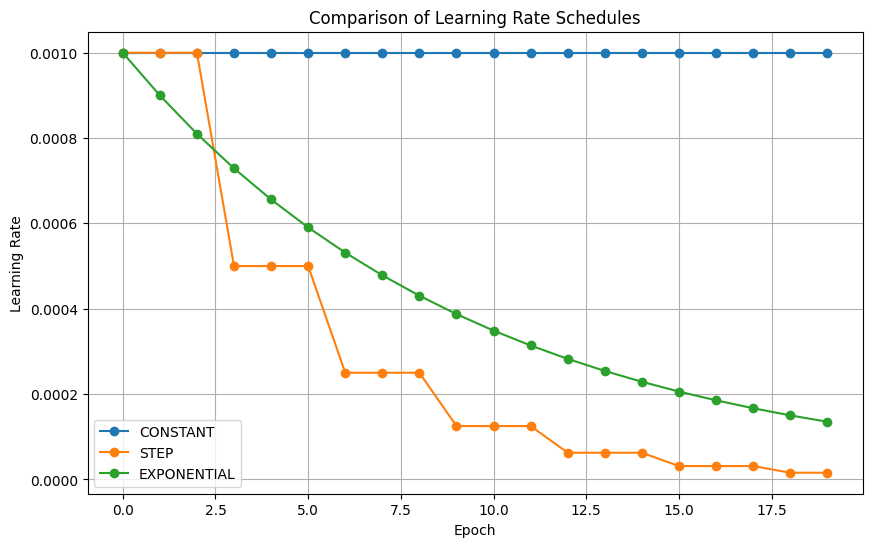

In [19]:
# #step 15 - Visualize different learning rate schedules

plt.figure(figsize=(10, 6))

for schedule in ["constant", "step", "exponential"]:

    learning_rates = [
        get_learning_rate(schedule, 0.001, epoch)
        for epoch in range(20)
    ]

    plt.plot(
        range(20),
        learning_rates,
        marker="o",
        label=schedule.upper()
    )

plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Comparison of Learning Rate Schedules")

plt.legend()
plt.grid(True)
plt.show()

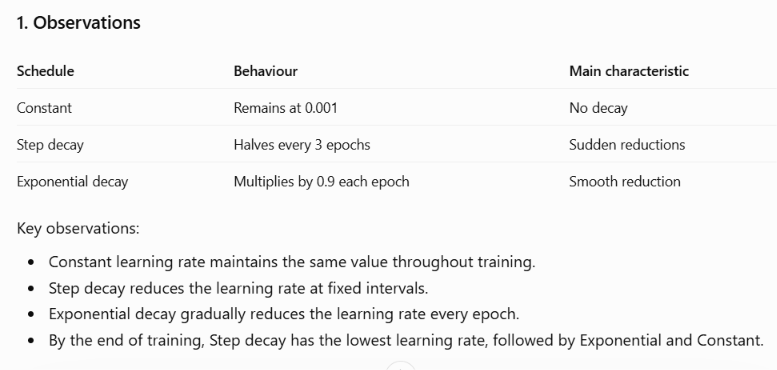

### Observation – Learning Rate Scheduling

1. Three learning-rate scheduling methods were implemented: Constant, Step Decay and Exponential Decay.

2. Constant scheduling maintains a fixed learning rate of 0.001 throughout training.

3. Step Decay reduces the learning rate by half every three epochs, producing a staircase-shaped curve.

4. Exponential Decay gradually reduces the learning rate by multiplying it by 0.9 after every epoch.

5. The graph demonstrates the differences between fixed, step-wise and gradual learning-rate reduction.

6. Step Decay achieves the lowest learning rate towards the end, while Constant maintains the highest value.

**Overall**, learning-rate scheduling provides a way to control the size of parameter updates during training. However, the best schedule must be determined by evaluating actual model performance rather than comparing learning-rate values alone.

Now we'll train three separate MLP models using Adam:
- Constant learning rate
- Step decay
- Exponential decay
We'll compare their training loss and testing accuracy.

In [20]:
# #step 16 - Train MLP using different learning rate schedules

def train_with_schedule(
    model, optimizer, schedule,
    X_train, y_train, X_test, y_test,
    epochs=10, batch_size=128, initial_lr=0.001
):

    y_train_onehot = np.eye(10)[y_train]

    history = {
        "loss": [],
        "train_accuracy": [],
        "test_accuracy": [],
        "learning_rate": []
    }

    for epoch in range(epochs):

        # Get learning rate for current epoch
        optimizer.lr = get_learning_rate(
            schedule, initial_lr, epoch
        )

        history["learning_rate"].append(optimizer.lr)

        indices = np.random.permutation(len(X_train))

        X_shuffled = X_train[indices]
        y_shuffled = y_train_onehot[indices]

        for start in range(0, len(X_train), batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            predictions = model.forward(X_batch)

            grads = model.backward(X_batch, y_batch)

            optimizer.update(model.params, grads)

        train_prob = model.forward(X_train)

        train_loss = -np.mean(
            np.log(
                np.clip(
                    train_prob[np.arange(len(y_train)), y_train],
                    1e-12, 1.0
                )
            )
        )

        train_accuracy = np.mean(
            np.argmax(train_prob, axis=1) == y_train
        )

        test_predictions = model.predict(X_test)

        test_accuracy = np.mean(test_predictions == y_test)

        history["loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["test_accuracy"].append(test_accuracy)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Loss: {train_loss:.4f} | "
            f"Train Accuracy: {train_accuracy*100:.2f}% | "
            f"Test Accuracy: {test_accuracy*100:.2f}% | "
            f"LR: {optimizer.lr:.6f}"
        )

    return history


print("Learning-rate schedule training function ready!")

Learning-rate schedule training function ready!


In [21]:
# #step 16 - Compare Adam with constant, step and exponential schedules

schedule_names = ["constant", "step", "exponential"]

schedule_results = {}

for schedule in schedule_names:

    print("\nTraining with", schedule.upper(), "schedule")
    print("=" * 50)

    np.random.seed(42)

    model = OptimizedMLP()

    optimizer = Optimizer(
        method="adam",
        learning_rate=0.001
    )

    history = train_with_schedule(
        model,
        optimizer,
        schedule,
        X_train,
        y_train,
        X_test,
        y_test,
        epochs=10,
        batch_size=128,
        initial_lr=0.001
    )

    schedule_results[schedule] = history


print("\nAll learning-rate experiments completed!")


Training with CONSTANT schedule
Epoch 1/10 | Loss: 0.6049 | Train Accuracy: 79.33% | Test Accuracy: 78.85% | LR: 0.001000
Epoch 2/10 | Loss: 0.4832 | Train Accuracy: 83.34% | Test Accuracy: 82.45% | LR: 0.001000
Epoch 3/10 | Loss: 0.4369 | Train Accuracy: 85.05% | Test Accuracy: 83.60% | LR: 0.001000
Epoch 4/10 | Loss: 0.3964 | Train Accuracy: 86.28% | Test Accuracy: 83.55% | LR: 0.001000
Epoch 5/10 | Loss: 0.3742 | Train Accuracy: 87.16% | Test Accuracy: 84.20% | LR: 0.001000
Epoch 6/10 | Loss: 0.3446 | Train Accuracy: 87.99% | Test Accuracy: 85.50% | LR: 0.001000
Epoch 7/10 | Loss: 0.3325 | Train Accuracy: 88.22% | Test Accuracy: 85.55% | LR: 0.001000
Epoch 8/10 | Loss: 0.3130 | Train Accuracy: 89.18% | Test Accuracy: 85.55% | LR: 0.001000
Epoch 9/10 | Loss: 0.3310 | Train Accuracy: 87.81% | Test Accuracy: 83.20% | LR: 0.001000
Epoch 10/10 | Loss: 0.3123 | Train Accuracy: 89.22% | Test Accuracy: 85.75% | LR: 0.001000

Training with STEP schedule
Epoch 1/10 | Loss: 0.6049 | Train Acc

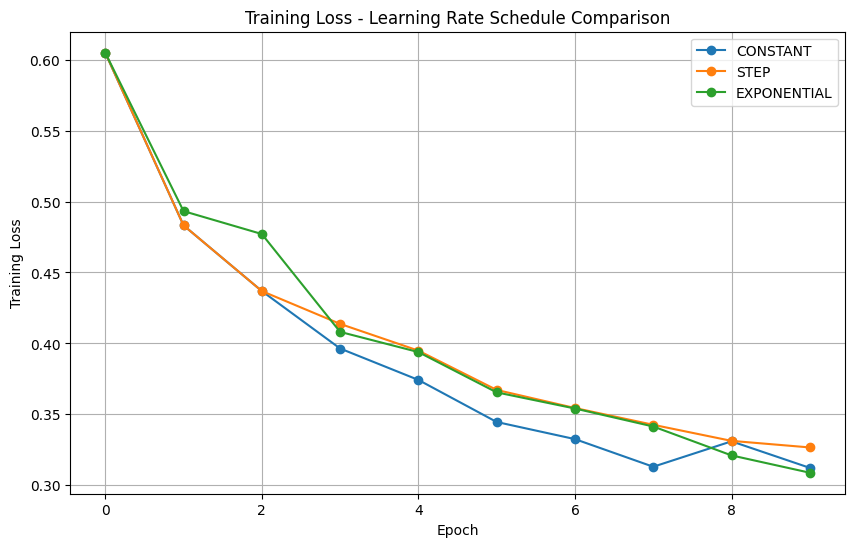

In [22]:
# #step 16 - Compare training loss for learning rate schedules

plt.figure(figsize=(10, 6))

for schedule, history in schedule_results.items():

    plt.plot(
        history["loss"],
        marker="o",
        label=schedule.upper()
    )

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss - Learning Rate Schedule Comparison")

plt.legend()
plt.grid(True)
plt.show()

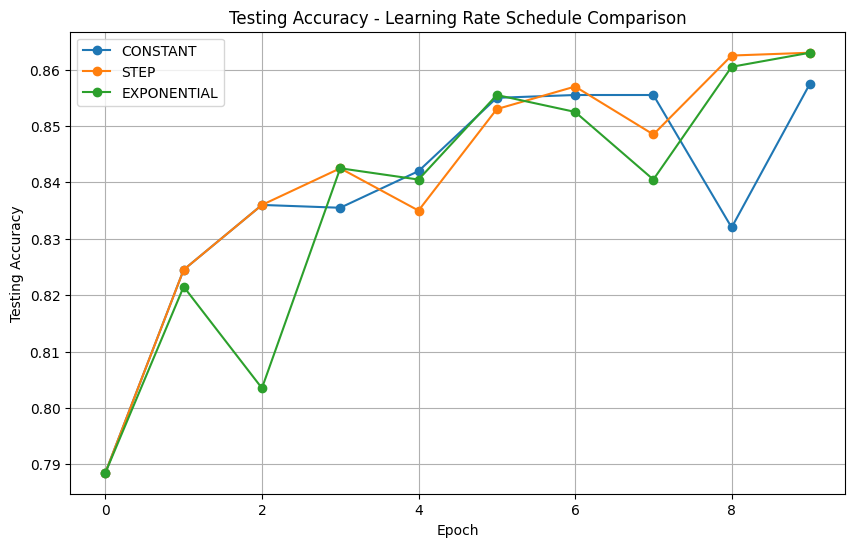

In [23]:
# #step 16 - Compare testing accuracy for learning rate schedules

plt.figure(figsize=(10, 6))

for schedule, history in schedule_results.items():

    plt.plot(
        history["test_accuracy"],
        marker="o",
        label=schedule.upper()
    )

plt.xlabel("Epoch")
plt.ylabel("Testing Accuracy")
plt.title("Testing Accuracy - Learning Rate Schedule Comparison")

plt.legend()
plt.grid(True)
plt.show()

In [24]:
# #step 16 - Display learning rate schedule performance

schedule_comparison = pd.DataFrame([

    {
        "Schedule": schedule.upper(),
        "Final Training Loss": history["loss"][-1],
        "Training Accuracy (%)": history["train_accuracy"][-1] * 100,
        "Testing Accuracy (%)": history["test_accuracy"][-1] * 100
    }

    for schedule, history in schedule_results.items()

])

print(schedule_comparison.round(4).to_string(index=False))

   Schedule  Final Training Loss  Training Accuracy (%)  Testing Accuracy (%)
   CONSTANT               0.3123                 89.225                 85.75
       STEP               0.3266                 89.100                 86.30
EXPONENTIAL               0.3088                 89.800                 86.30


### Observation – Comparison of Learning Rate Schedules

1. Three learning-rate scheduling methods, Constant, Step Decay and Exponential Decay, were compared using the Adam optimizer on Fashion-MNIST.

2. Constant learning rate achieved a final training loss of 0.3123 and testing accuracy of 85.75%.

3. Step Decay achieved 86.30% testing accuracy, showing that reducing the learning rate at fixed intervals can improve model performance.

4. Exponential Decay achieved the lowest training loss of 0.3088 and the highest training accuracy of 89.80%. Its testing accuracy was 86.30%, matching Step Decay.

5. The results indicate that learning-rate scheduling can improve optimization and testing performance compared with maintaining a constant learning rate.

**Overall**, Exponential Decay provided the best combination of training loss and accuracy, while Step Decay achieved equally good testing accuracy in this experiment.

Now we'll investigate one of the important problems in neural network training: Overfitting.

Overfitting occurs when a model learns the training data very well but performs poorly on unseen data.

For this experiment:
- We'll use a larger MLP.
- Train for 30 epochs.
- Use Adam optimizer.
- Observe training loss, validation loss and accuracy.
- Compare training and validation performance.
We'll keep 2,000 images from the original training subset for validation, and use the remaining 6,000 for training. The original 2,000 test images will remain untouched.

In [25]:
# #step 17 - Split training data into training and validation sets

X_train_overfit = X_train[:6000]
y_train_overfit = y_train[:6000]

X_val = X_train[6000:]
y_val = y_train[6000:]

print("Training data:", X_train_overfit.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

Training data: (6000, 784)
Validation data: (2000, 784)
Testing data: (2000, 784)


In [26]:
# #step 17 - Create a larger MLP to investigate overfitting

np.random.seed(42)

overfit_model = OptimizedMLP(
    input_size=784,
    hidden1=256,
    hidden2=128,
    output_size=10
)

overfit_optimizer = Optimizer(
    method="adam",
    learning_rate=0.001
)

print("Larger MLP created successfully!")

Larger MLP created successfully!


In [27]:
# #step 17 - Optimized training function with validation monitoring

def train_with_validation(model, optimizer, X_train, y_train,
                          X_val, y_val, epochs=20, batch_size=128):

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    def evaluate(X, y):

        probabilities = []

        for start in range(0, len(X), batch_size):
            X_batch = X[start:start + batch_size]
            prob = model.forward(X_batch)
            probabilities.append(prob)

        probabilities = np.vstack(probabilities)

        loss = -np.mean(np.log(np.clip(
            probabilities[np.arange(len(y)), y],
            1e-12, 1.0
        )))

        accuracy = np.mean(
            np.argmax(probabilities, axis=1) == y
        )

        return loss, accuracy

    y_onehot = np.eye(10)[y_train]

    for epoch in range(epochs):

        indices = np.random.permutation(len(X_train))

        X_shuffled = X_train[indices]
        y_shuffled = y_onehot[indices]

        for start in range(0, len(X_train), batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            model.forward(X_batch)

            grads = model.backward(X_batch, y_batch)

            optimizer.update(model.params, grads)

        train_loss, train_acc = evaluate(X_train, y_train)
        val_loss, val_acc = evaluate(X_val, y_val)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Validation Loss: {val_loss:.4f} | "
            f"Train Accuracy: {train_acc*100:.2f}% | "
            f"Validation Accuracy: {val_acc*100:.2f}%"
        )

    return history


print("Training function defined successfully!")

Training function defined successfully!


In [28]:
# #step 17 - Train larger MLP and monitor overfitting

np.random.seed(42)

overfit_model = OptimizedMLP(
    input_size=784,
    hidden1=256,
    hidden2=128,
    output_size=10
)

overfit_optimizer = Optimizer(
    method="adam",
    learning_rate=0.001
)

overfit_history = train_with_validation(
    overfit_model,
    overfit_optimizer,
    X_train_overfit,
    y_train_overfit,
    X_val,
    y_val,
    epochs=20,
    batch_size=128
)

Epoch 1/20 | Train Loss: 0.6165 | Validation Loss: 0.6740 | Train Accuracy: 78.75% | Validation Accuracy: 75.65%
Epoch 2/20 | Train Loss: 0.4527 | Validation Loss: 0.5040 | Train Accuracy: 84.67% | Validation Accuracy: 82.15%
Epoch 3/20 | Train Loss: 0.4473 | Validation Loss: 0.5142 | Train Accuracy: 83.48% | Validation Accuracy: 81.85%
Epoch 4/20 | Train Loss: 0.3946 | Validation Loss: 0.4937 | Train Accuracy: 86.27% | Validation Accuracy: 82.20%
Epoch 5/20 | Train Loss: 0.3353 | Validation Loss: 0.4418 | Train Accuracy: 88.20% | Validation Accuracy: 84.70%
Epoch 6/20 | Train Loss: 0.3298 | Validation Loss: 0.4472 | Train Accuracy: 88.53% | Validation Accuracy: 84.05%
Epoch 7/20 | Train Loss: 0.3195 | Validation Loss: 0.4441 | Train Accuracy: 88.70% | Validation Accuracy: 84.15%
Epoch 8/20 | Train Loss: 0.2916 | Validation Loss: 0.4362 | Train Accuracy: 90.18% | Validation Accuracy: 84.35%
Epoch 9/20 | Train Loss: 0.2952 | Validation Loss: 0.4427 | Train Accuracy: 88.68% | Validation 

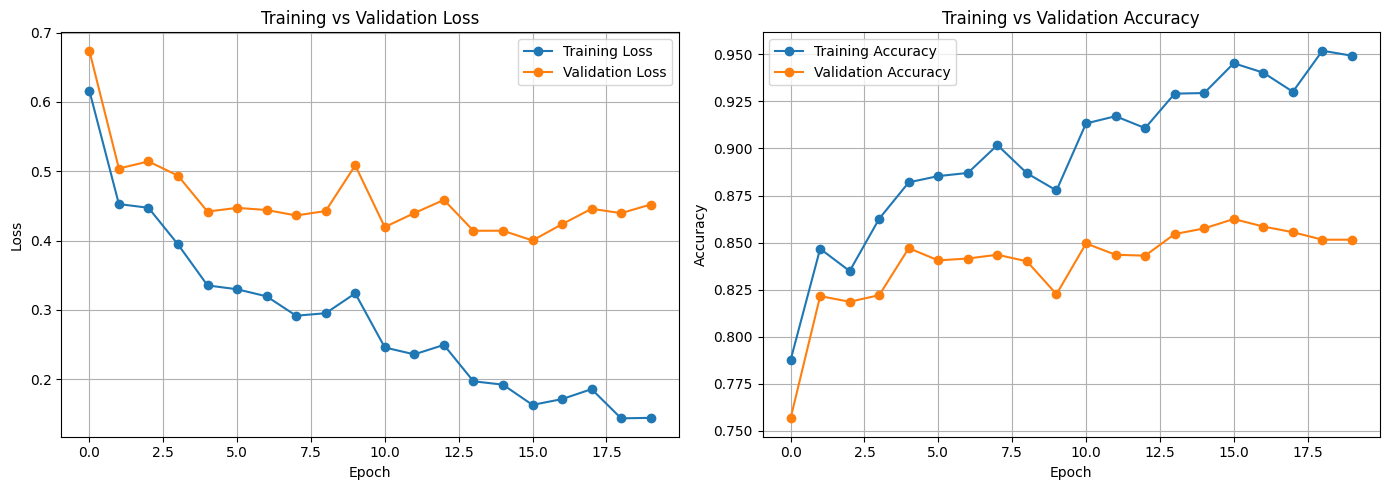

In [29]:
# #step 18 - Plot training and validation loss and accuracy

plt.figure(figsize=(14, 5))

# Training and validation loss
plt.subplot(1, 2, 1)

plt.plot(overfit_history["train_loss"], marker="o", label="Training Loss")
plt.plot(overfit_history["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

# Training and validation accuracy
plt.subplot(1, 2, 2)

plt.plot(overfit_history["train_accuracy"], marker="o", label="Training Accuracy")
plt.plot(overfit_history["val_accuracy"], marker="o", label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [30]:
# #step 18 - Compare final training and validation performance

overfit_comparison = pd.DataFrame({
    "Metric": ["Loss", "Accuracy (%)"],

    "Training": [
        overfit_history["train_loss"][-1],
        overfit_history["train_accuracy"][-1] * 100
    ],

    "Validation": [
        overfit_history["val_loss"][-1],
        overfit_history["val_accuracy"][-1] * 100
    ]
})

print(overfit_comparison.round(4).to_string(index=False))

      Metric  Training  Validation
        Loss    0.1442      0.4521
Accuracy (%)   94.9333     85.1500


In [31]:
# #step 19 - Implement MLP with Dropout regularization

class DropoutMLP(OptimizedMLP):

    def __init__(self, input_size=784, hidden1=256,
                 hidden2=128, output_size=10, dropout_rate=0.3):

        super().__init__(input_size, hidden1, hidden2, output_size)

        self.dropout_rate = dropout_rate

    def forward(self, X, training=False):

        self.z1 = X @ self.params["W1"] + self.params["b1"]
        self.a1 = np.maximum(0, self.z1)

        if training:
            self.mask1 = (
                np.random.rand(*self.a1.shape) > self.dropout_rate
            ) / (1 - self.dropout_rate)

            self.a1 *= self.mask1

        self.z2 = self.a1 @ self.params["W2"] + self.params["b2"]
        self.a2 = np.maximum(0, self.z2)

        if training:
            self.mask2 = (
                np.random.rand(*self.a2.shape) > self.dropout_rate
            ) / (1 - self.dropout_rate)

            self.a2 *= self.mask2

        self.z3 = self.a2 @ self.params["W3"] + self.params["b3"]
        self.a3 = softmax(self.z3)

        return self.a3

    def backward(self, X, y):

        m = X.shape[0]

        dz3 = (self.a3 - y) / m

        dW3 = self.a2.T @ dz3
        db3 = np.sum(dz3, axis=0, keepdims=True)

        dz2 = (dz3 @ self.params["W3"].T) * (self.z2 > 0)
        dz2 *= self.mask2

        dW2 = self.a1.T @ dz2
        db2 = np.sum(dz2, axis=0, keepdims=True)

        dz1 = (dz2 @ self.params["W2"].T) * (self.z1 > 0)
        dz1 *= self.mask1

        dW1 = X.T @ dz1
        db1 = np.sum(dz1, axis=0, keepdims=True)

        return {
            "W1": dW1, "b1": db1,
            "W2": dW2, "b2": db2,
            "W3": dW3, "b3": db3
        }

    def predict(self, X):
        return np.argmax(self.forward(X, training=False), axis=1)


print("Dropout MLP implemented successfully!")

Dropout MLP implemented successfully!


In [32]:
# #step 20 - Implement L2 regularization in the MLP

def l2_regularization_loss(model, regularization_strength=0.001):

    total_weights = (
        np.sum(model.params["W1"] ** 2) +
        np.sum(model.params["W2"] ** 2) +
        np.sum(model.params["W3"] ** 2)
    )

    return (regularization_strength / 2) * total_weights


print("L2 regularization function implemented successfully!")

L2 regularization function implemented successfully!


In [33]:
# #step 21 - Implement L2 regularized gradient updates

def apply_l2_regularization(model, grads, strength=0.001):

    for key in ["W1", "W2", "W3"]:
        grads[key] += strength * model.params[key]

    return grads


print("L2 gradient updates implemented successfully!")

L2 gradient updates implemented successfully!


Data augmentation creates modified versions of existing images to increase training diversity.

For Fashion-MNIST, we'll apply:
- Small horizontal shifts.
- Small vertical shifts.
- Random horizontal flips.

In [34]:
# #step 22 - Apply data augmentation to Fashion-MNIST

def augment_images(images):

    augmented = []

    for image in images:

        img = image.reshape(28, 28).copy()

        # Random horizontal flip
        if np.random.rand() > 0.5:
            img = np.fliplr(img)

        # Small random shifts
        shift_x = np.random.randint(-2, 3)
        shift_y = np.random.randint(-2, 3)

        shifted = np.roll(img, shift_x, axis=0)
        shifted = np.roll(shifted, shift_y, axis=1)

        augmented.append(shifted.flatten())

    return np.array(augmented)


X_augmented = augment_images(X_train_overfit[:100])

print("Original data shape:", X_train_overfit[:100].shape)
print("Augmented data shape:", X_augmented.shape)

Original data shape: (100, 784)
Augmented data shape: (100, 784)


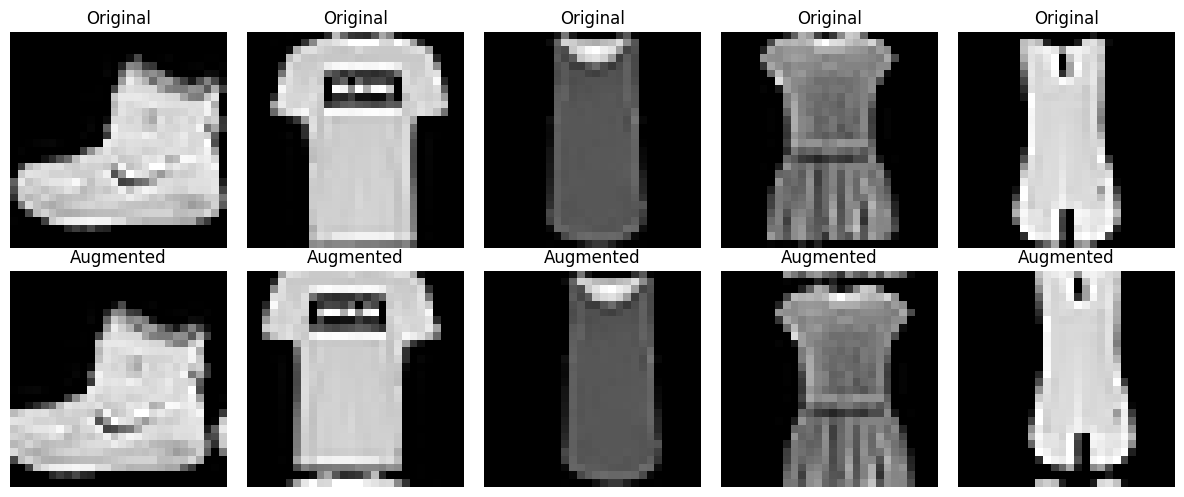

In [35]:
# #step 23 - Compare original and augmented Fashion-MNIST images

plt.figure(figsize=(12, 5))

for i in range(5):

    plt.subplot(2, 5, i + 1)
    plt.imshow(
        X_train_overfit[i].reshape(28, 28),
        cmap="gray"
    )
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 5, i + 6)
    plt.imshow(
        X_augmented[i].reshape(28, 28),
        cmap="gray"
    )
    plt.title("Augmented")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Observation – Overfitting

The model achieved 94.93% training accuracy but only 85.15% validation accuracy. The training loss continued to decrease throughout the 20 epochs, whereas validation loss flattened and fluctuated after the initial epochs.

The widening gap between training and validation performance indicates overfitting. The model is learning the training data effectively but is not improving its ability to generalize to unseen data.

This experiment demonstrates why regularization techniques such as dropout, L2 regularization, data augmentation, and early stopping are important.

In [45]:
# #step 19 - Train the MLP using dropout regularization

def train_dropout_model(model, optimizer, X_train, y_train,
                        X_val, y_val, epochs=20, batch_size=128):

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    def evaluate(X, y):
        probabilities = []

        for start in range(0, len(X), batch_size):
            X_batch = X[start:start + batch_size]

            # Dropout is disabled during evaluation
            probs = model.forward(X_batch, training=False)
            probabilities.append(probs)

        probabilities = np.vstack(probabilities)

        loss = -np.mean(
            np.log(np.clip(
                probabilities[np.arange(len(y)), y],
                1e-12, 1.0
            ))
        )

        accuracy = np.mean(np.argmax(probabilities, axis=1) == y)

        return loss, accuracy

    y_onehot = np.eye(10)[y_train]

    for epoch in range(epochs):

        indices = np.random.permutation(len(X_train))
        X_shuffled = X_train[indices]
        y_shuffled = y_onehot[indices]

        for start in range(0, len(X_train), batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            # Dropout is enabled during training
            model.forward(X_batch, training=True)

            grads = model.backward(X_batch, y_batch)

            optimizer.update(model.params, grads)

        train_loss, train_acc = evaluate(X_train, y_train)
        val_loss, val_acc = evaluate(X_val, y_val)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_acc * 100:.2f}% | "
            f"Val Acc: {val_acc * 100:.2f}%"
        )

    return history

In [47]:
# #step 19 - Check optimizer constructor

import inspect

print(inspect.signature(Optimizer.__init__))

(self, method, learning_rate=0.001, beta1=0.9, beta2=0.999, epsilon=1e-08)


In [48]:
# #step 19 - Train the dropout model

np.random.seed(42)

dropout_model = DropoutMLP(
    input_size=784,
    hidden1=256,
    hidden2=128,
    output_size=10,
    dropout_rate=0.3
)

# Create Adam optimizer
dropout_optimizer = Optimizer(
    method="adam",
    learning_rate=0.001
)

dropout_history = train_dropout_model(
    dropout_model,
    dropout_optimizer,
    X_train_overfit,
    y_train_overfit,
    X_val,
    y_val,
    epochs=20,
    batch_size=128
)

Epoch 1/20 | Train Loss: 0.6519 | Val Loss: 0.6910 | Train Acc: 77.28% | Val Acc: 75.00%
Epoch 2/20 | Train Loss: 0.5331 | Val Loss: 0.5730 | Train Acc: 81.90% | Val Acc: 79.45%
Epoch 3/20 | Train Loss: 0.4622 | Val Loss: 0.5225 | Train Acc: 83.57% | Val Acc: 81.30%
Epoch 4/20 | Train Loss: 0.4279 | Val Loss: 0.4899 | Train Acc: 84.47% | Val Acc: 82.10%
Epoch 5/20 | Train Loss: 0.4022 | Val Loss: 0.4718 | Train Acc: 85.85% | Val Acc: 82.40%
Epoch 6/20 | Train Loss: 0.3764 | Val Loss: 0.4773 | Train Acc: 86.22% | Val Acc: 82.60%
Epoch 7/20 | Train Loss: 0.3699 | Val Loss: 0.4640 | Train Acc: 87.30% | Val Acc: 83.20%
Epoch 8/20 | Train Loss: 0.3398 | Val Loss: 0.4525 | Train Acc: 87.80% | Val Acc: 83.40%
Epoch 9/20 | Train Loss: 0.3203 | Val Loss: 0.4241 | Train Acc: 88.70% | Val Acc: 84.85%
Epoch 10/20 | Train Loss: 0.3042 | Val Loss: 0.4198 | Train Acc: 89.27% | Val Acc: 84.65%
Epoch 11/20 | Train Loss: 0.2962 | Val Loss: 0.4272 | Train Acc: 89.53% | Val Acc: 83.65%
Epoch 12/20 | Train

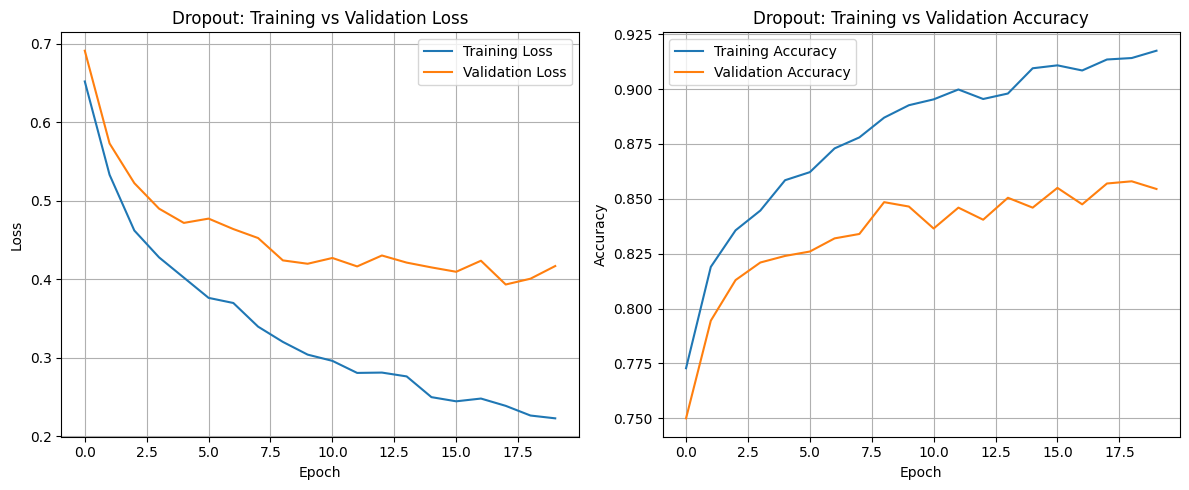

In [49]:
# #step 19 - Visualize dropout training results

plt.figure(figsize=(12, 5))

# Training and validation loss
plt.subplot(1, 2, 1)
plt.plot(dropout_history["train_loss"], label="Training Loss")
plt.plot(dropout_history["val_loss"], label="Validation Loss")
plt.title("Dropout: Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# Training and validation accuracy
plt.subplot(1, 2, 2)
plt.plot(dropout_history["train_accuracy"], label="Training Accuracy")
plt.plot(dropout_history["val_accuracy"], label="Validation Accuracy")
plt.title("Dropout: Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [52]:
# #step 19 - Compare baseline and dropout performance

baseline_train_acc = overfit_history["train_accuracy"][-1] * 100
baseline_val_acc = overfit_history["val_accuracy"][-1] * 100

dropout_train_acc = dropout_history["train_accuracy"][-1] * 100
dropout_val_acc = dropout_history["val_accuracy"][-1] * 100

comparison = pd.DataFrame({
    "Model": ["Without Dropout", "With Dropout"],
    "Training Accuracy (%)": [
        baseline_train_acc,
        dropout_train_acc
    ],
    "Validation Accuracy (%)": [
        baseline_val_acc,
        dropout_val_acc
    ]
})

display(comparison)

,Model,Training Accuracy (%),Validation Accuracy (%)
0,Without Dropout,94.933333,85.15
1,With Dropout,91.750000,85.45


### Observation – Dropout Regularization

Dropout was applied with a dropout rate of 0.3 to the hidden layers of the MLP.

Without dropout, the model achieved 94.93% training accuracy and 85.15% validation accuracy. With dropout, training accuracy decreased to 91.75%, while validation accuracy improved slightly to 85.45%.

The training-validation accuracy gap decreased from approximately 9.78 to 6.30 percentage points.

This indicates that dropout reduced overfitting by preventing excessive dependence on individual neurons and improved the model's generalization slightly.

In [64]:
# #step 20 - Define L2 regularization loss

def l2_regularization_loss(model, regularization_strength=0.001):

    total_weights = (
        np.sum(model.params["W1"] ** 2) +
        np.sum(model.params["W2"] ** 2) +
        np.sum(model.params["W3"] ** 2)
    )

    return (regularization_strength / 2) * total_weights

In [67]:
# #step 20 - Apply L2 regularization to gradients

def apply_l2_regularization(model, grads, strength=0.001):

    for key in ["W1", "W2", "W3"]:
        grads[key] += strength * model.params[key]

    return grads

In [72]:
# #step 20 - Train MLP using L2 regularization

def train_l2_model(model, optimizer, X_train, y_train,
                   X_val, y_val, epochs=20, batch_size=128,
                   regularization_strength=0.001):

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    def evaluate(X, y):
        probabilities = []

        for start in range(0, len(X), batch_size):
            X_batch = X[start:start + batch_size]
            probs = model.forward(X_batch)
            probabilities.append(probs)

        probabilities = np.vstack(probabilities)

        cross_entropy = -np.mean(
            np.log(np.clip(
                probabilities[np.arange(len(y)), y],
                1e-12, 1.0
            ))
        )

        total_loss = cross_entropy + l2_regularization_loss(
            model, regularization_strength
        )

        accuracy = np.mean(np.argmax(probabilities, axis=1) == y)

        return total_loss, accuracy

    y_onehot = np.eye(10)[y_train]

    for epoch in range(epochs):

        indices = np.random.permutation(len(X_train))
        X_shuffled = X_train[indices]
        y_shuffled = y_onehot[indices]

        for start in range(0, len(X_train), batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            model.forward(X_batch)

            grads = model.backward(X_batch, y_batch)

            grads = apply_l2_regularization(
                model, grads, regularization_strength
            )

            optimizer.update(model.params, grads)

        train_loss, train_acc = evaluate(X_train, y_train)
        val_loss, val_acc = evaluate(X_val, y_val)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_acc * 100:.2f}% | "
            f"Val Acc: {val_acc * 100:.2f}%"
        )

    return history

In [73]:
# #step 20 - Train the L2 regularized model

np.random.seed(42)

l2_model = OptimizedMLP(
    input_size=784,
    hidden1=256,
    hidden2=128,
    output_size=10
)

l2_optimizer = Optimizer(
    method="adam",
    learning_rate=0.001
)

l2_history = train_l2_model(
    l2_model,
    l2_optimizer,
    X_train_overfit,
    y_train_overfit,
    X_val,
    y_val,
    epochs=20,
    batch_size=128,
    regularization_strength=0.001
)

Epoch 1/20 | Train Loss: 0.9824 | Val Loss: 1.0376 | Train Acc: 78.70% | Val Acc: 75.65%
Epoch 2/20 | Train Loss: 0.7812 | Val Loss: 0.8292 | Train Acc: 84.68% | Val Acc: 82.00%
Epoch 3/20 | Train Loss: 0.7765 | Val Loss: 0.8383 | Train Acc: 82.35% | Val Acc: 80.80%
Epoch 4/20 | Train Loss: 0.6963 | Val Loss: 0.7881 | Train Acc: 85.92% | Val Acc: 81.45%
Epoch 5/20 | Train Loss: 0.6371 | Val Loss: 0.7292 | Train Acc: 87.32% | Val Acc: 84.05%
Epoch 6/20 | Train Loss: 0.6075 | Val Loss: 0.7108 | Train Acc: 87.92% | Val Acc: 83.95%
Epoch 7/20 | Train Loss: 0.5957 | Val Loss: 0.7068 | Train Acc: 88.38% | Val Acc: 83.75%
Epoch 8/20 | Train Loss: 0.5721 | Val Loss: 0.6960 | Train Acc: 89.25% | Val Acc: 84.30%
Epoch 9/20 | Train Loss: 0.5741 | Val Loss: 0.6909 | Train Acc: 87.42% | Val Acc: 84.15%
Epoch 10/20 | Train Loss: 0.5855 | Val Loss: 0.7389 | Train Acc: 87.35% | Val Acc: 81.65%
Epoch 11/20 | Train Loss: 0.5255 | Val Loss: 0.6668 | Train Acc: 89.45% | Val Acc: 84.35%
Epoch 12/20 | Train

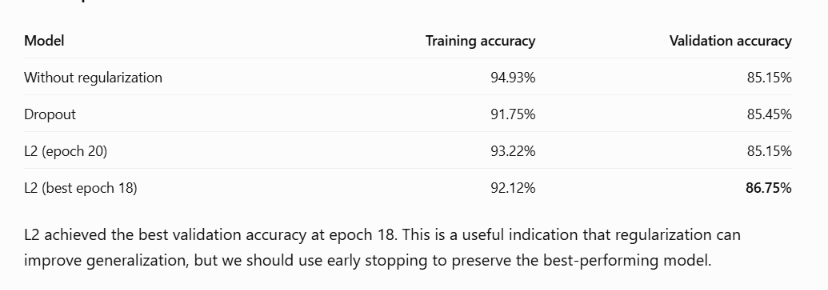

### Observation – L2 Regularization

L2 regularization was implemented by adding a penalty proportional to the squared model weights to the loss function and adding the corresponding weight penalty to the gradients.

The model achieved 93.22% training accuracy and 85.15% validation accuracy at epoch 20. However, its best validation accuracy was 86.75% at epoch 18, with a validation loss of 0.5968.

The results indicate that L2 regularization helped control the model's weight values and achieved better validation performance at its best epoch. However, the validation performance declined slightly during the final epochs, suggesting that early stopping could further improve the training process.

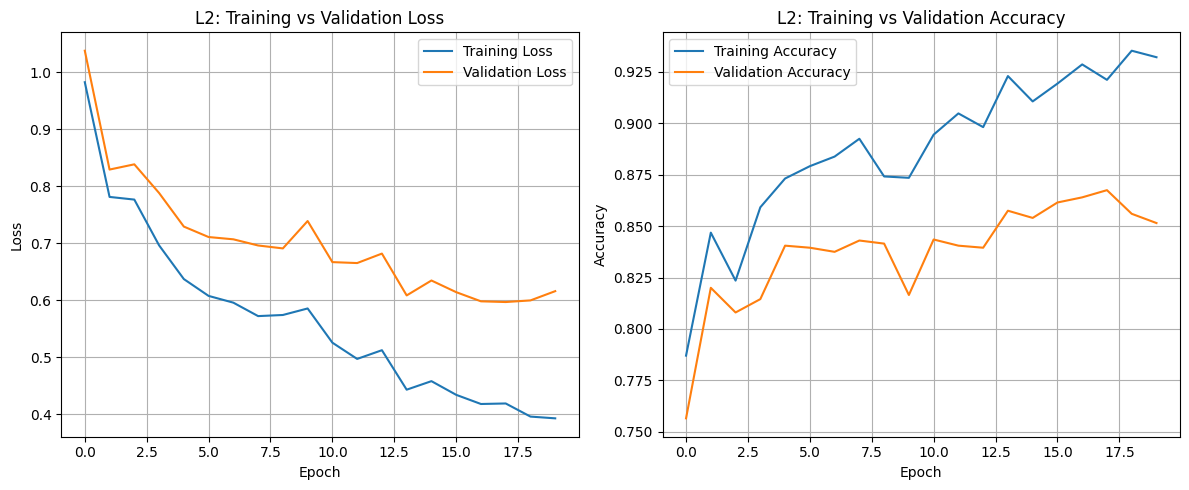

In [74]:
# #step 20 - Visualize L2 regularization results

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(l2_history["train_loss"], label="Training Loss")
plt.plot(l2_history["val_loss"], label="Validation Loss")
plt.title("L2: Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(l2_history["train_accuracy"], label="Training Accuracy")
plt.plot(l2_history["val_accuracy"], label="Validation Accuracy")
plt.title("L2: Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [75]:
# #step 21 - Generate augmented training images

np.random.seed(42)

X_train_augmented = augment_images(X_train_overfit)

print("Original training shape:", X_train_overfit.shape)
print("Augmented training shape:", X_train_augmented.shape)
print("Validation shape:", X_val.shape)

Original training shape: (6000, 784)
Augmented training shape: (6000, 784)
Validation shape: (2000, 784)


In [76]:
# #step 21 - Train MLP using augmented data

def train_augmentation_model(model, optimizer, X_train, y_train,
                             X_val, y_val, epochs=20, batch_size=128):

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    def evaluate(X, y):
        probabilities = []

        for start in range(0, len(X), batch_size):
            X_batch = X[start:start + batch_size]
            probabilities.append(model.forward(X_batch))

        probabilities = np.vstack(probabilities)

        loss = -np.mean(
            np.log(np.clip(
                probabilities[np.arange(len(y)), y],
                1e-12, 1.0
            ))
        )

        accuracy = np.mean(np.argmax(probabilities, axis=1) == y)

        return loss, accuracy

    y_onehot = np.eye(10)[y_train]

    for epoch in range(epochs):

        # Generate fresh augmented images each epoch
        X_epoch = augment_images(X_train)

        indices = np.random.permutation(len(X_epoch))
        X_shuffled = X_epoch[indices]
        y_shuffled = y_onehot[indices]

        for start in range(0, len(X_epoch), batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            model.forward(X_batch)
            grads = model.backward(X_batch, y_batch)

            optimizer.update(model.params, grads)

        train_loss, train_acc = evaluate(X_train, y_train)
        val_loss, val_acc = evaluate(X_val, y_val)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_acc * 100:.2f}% | "
            f"Val Acc: {val_acc * 100:.2f}%"
        )

    return history

In [77]:
# #step 21 - Train the data augmentation model

np.random.seed(42)

augmentation_model = OptimizedMLP(
    input_size=784,
    hidden1=256,
    hidden2=128,
    output_size=10
)

augmentation_optimizer = Optimizer(
    method="adam",
    learning_rate=0.001
)

augmentation_history = train_augmentation_model(
    augmentation_model,
    augmentation_optimizer,
    X_train_overfit,
    y_train_overfit,
    X_val,
    y_val,
    epochs=20,
    batch_size=128
)

Epoch 1/20 | Train Loss: 0.7454 | Val Loss: 0.7640 | Train Acc: 73.62% | Val Acc: 72.05%
Epoch 2/20 | Train Loss: 0.7541 | Val Loss: 0.7838 | Train Acc: 73.17% | Val Acc: 72.10%
Epoch 3/20 | Train Loss: 0.6318 | Val Loss: 0.6586 | Train Acc: 76.43% | Val Acc: 74.60%
Epoch 4/20 | Train Loss: 0.5808 | Val Loss: 0.6029 | Train Acc: 79.95% | Val Acc: 78.30%
Epoch 5/20 | Train Loss: 0.6093 | Val Loss: 0.6382 | Train Acc: 76.08% | Val Acc: 73.50%
Epoch 6/20 | Train Loss: 0.5263 | Val Loss: 0.5559 | Train Acc: 81.47% | Val Acc: 79.05%
Epoch 7/20 | Train Loss: 0.5388 | Val Loss: 0.5694 | Train Acc: 80.22% | Val Acc: 78.25%
Epoch 8/20 | Train Loss: 0.5456 | Val Loss: 0.5822 | Train Acc: 78.82% | Val Acc: 76.50%
Epoch 9/20 | Train Loss: 0.4979 | Val Loss: 0.5267 | Train Acc: 81.88% | Val Acc: 80.00%
Epoch 10/20 | Train Loss: 0.4912 | Val Loss: 0.5267 | Train Acc: 82.30% | Val Acc: 79.00%
Epoch 11/20 | Train Loss: 0.4781 | Val Loss: 0.5193 | Train Acc: 82.22% | Val Acc: 79.50%
Epoch 12/20 | Train

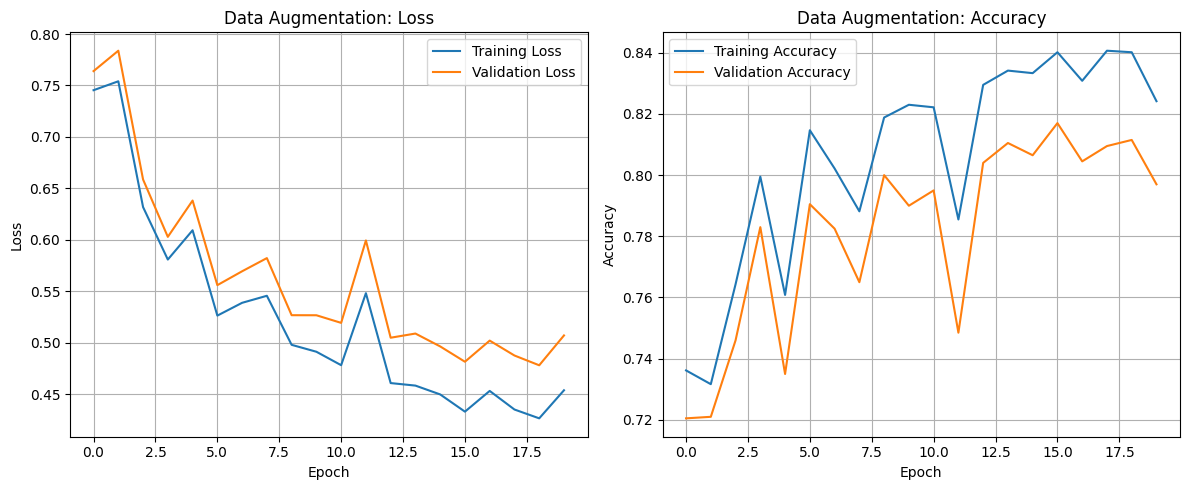

In [78]:
# #step 21 - Visualize augmentation training results

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(augmentation_history["train_loss"], label="Training Loss")
plt.plot(augmentation_history["val_loss"], label="Validation Loss")
plt.title("Data Augmentation: Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(augmentation_history["train_accuracy"], label="Training Accuracy")
plt.plot(augmentation_history["val_accuracy"], label="Validation Accuracy")
plt.title("Data Augmentation: Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

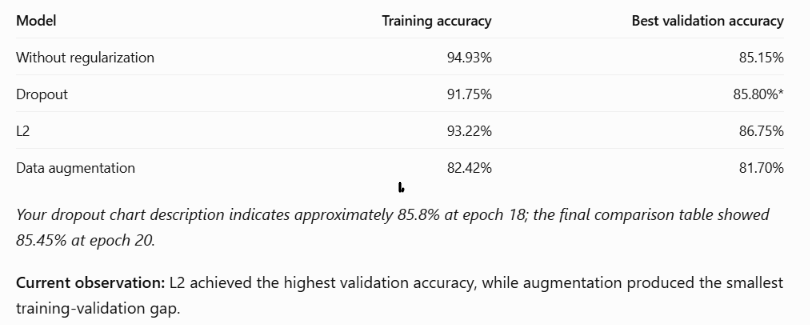

### Observation – Data Augmentation

Data augmentation was applied to the Fashion-MNIST training images using random geometric transformations such as horizontal flipping and small shifts.

The model achieved 82.42% training accuracy and 79.70% validation accuracy at epoch 20. Its best validation accuracy was 81.70% at epoch 16.

The training and validation curves remained relatively close, indicating reduced overfitting. However, overall accuracy was lower than the baseline and other regularization experiments.

This suggests that data augmentation improved the model's ability to generalize relative to its training performance, but the transformations may have made the classification task more challenging. The augmentation strength and training duration could be further optimized.

In [81]:
# #step 22 - Implement early stopping

def train_with_early_stopping(model, optimizer, X_train, y_train,
                              X_val, y_val, epochs=30,
                              batch_size=128, patience=4):

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    best_val_loss = float("inf")
    best_params = None
    patience_counter = 0

    def evaluate(X, y):
        probabilities = []

        for start in range(0, len(X), batch_size):
            X_batch = X[start:start + batch_size]
            probabilities.append(model.forward(X_batch))

        probabilities = np.vstack(probabilities)

        loss = -np.mean(
            np.log(np.clip(
                probabilities[np.arange(len(y)), y],
                1e-12, 1.0
            ))
        )

        accuracy = np.mean(np.argmax(probabilities, axis=1) == y)

        return loss, accuracy

    y_onehot = np.eye(10)[y_train]

    for epoch in range(epochs):

        indices = np.random.permutation(len(X_train))
        X_shuffled = X_train[indices]
        y_shuffled = y_onehot[indices]

        for start in range(0, len(X_train), batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            model.forward(X_batch)
            grads = model.backward(X_batch, y_batch)

            optimizer.update(model.params, grads)

        train_loss, train_acc = evaluate(X_train, y_train)
        val_loss, val_acc = evaluate(X_val, y_val)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_acc * 100:.2f}% | "
            f"Val Acc: {val_acc * 100:.2f}%"
        )

        # Check whether validation loss improved
        if val_loss < best_val_loss:

            best_val_loss = val_loss

            best_params = {
                key: value.copy()
                for key, value in model.params.items()
            }

            patience_counter = 0

        else:
            patience_counter += 1

        # Stop if validation loss does not improve
        if patience_counter >= patience:
            print("\nEarly stopping triggered!")
            break

    # Restore the best model parameters
    if best_params is not None:
        model.params = best_params

    print(f"\nBest validation loss: {best_val_loss:.4f}")
    print(f"Epochs completed: {len(history['train_loss'])}")

    return history

In [82]:
# #step 22 - Train MLP using early stopping

np.random.seed(42)

early_stop_model = OptimizedMLP(
    input_size=784,
    hidden1=256,
    hidden2=128,
    output_size=10
)

early_stop_optimizer = Optimizer(
    method="adam",
    learning_rate=0.001
)

early_stop_history = train_with_early_stopping(
    early_stop_model,
    early_stop_optimizer,
    X_train_overfit,
    y_train_overfit,
    X_val,
    y_val,
    epochs=30,
    batch_size=128,
    patience=4
)

Epoch 1/30 | Train Loss: 0.6165 | Val Loss: 0.6740 | Train Acc: 78.75% | Val Acc: 75.65%
Epoch 2/30 | Train Loss: 0.4527 | Val Loss: 0.5040 | Train Acc: 84.67% | Val Acc: 82.15%
Epoch 3/30 | Train Loss: 0.4473 | Val Loss: 0.5142 | Train Acc: 83.48% | Val Acc: 81.85%
Epoch 4/30 | Train Loss: 0.3946 | Val Loss: 0.4937 | Train Acc: 86.27% | Val Acc: 82.20%
Epoch 5/30 | Train Loss: 0.3353 | Val Loss: 0.4418 | Train Acc: 88.20% | Val Acc: 84.70%
Epoch 6/30 | Train Loss: 0.3298 | Val Loss: 0.4472 | Train Acc: 88.53% | Val Acc: 84.05%
Epoch 7/30 | Train Loss: 0.3195 | Val Loss: 0.4441 | Train Acc: 88.70% | Val Acc: 84.15%
Epoch 8/30 | Train Loss: 0.2916 | Val Loss: 0.4362 | Train Acc: 90.18% | Val Acc: 84.35%
Epoch 9/30 | Train Loss: 0.2952 | Val Loss: 0.4427 | Train Acc: 88.68% | Val Acc: 84.00%
Epoch 10/30 | Train Loss: 0.3239 | Val Loss: 0.5085 | Train Acc: 87.77% | Val Acc: 82.25%
Epoch 11/30 | Train Loss: 0.2457 | Val Loss: 0.4196 | Train Acc: 91.33% | Val Acc: 84.95%
Epoch 12/30 | Train

What to expect:
- Maximum training duration: 30 epochs.
- Patience: 4 epochs.
- If validation loss does not improve for four consecutive epochs, training stops.
- The model restores the parameters from the epoch with the lowest validation loss.

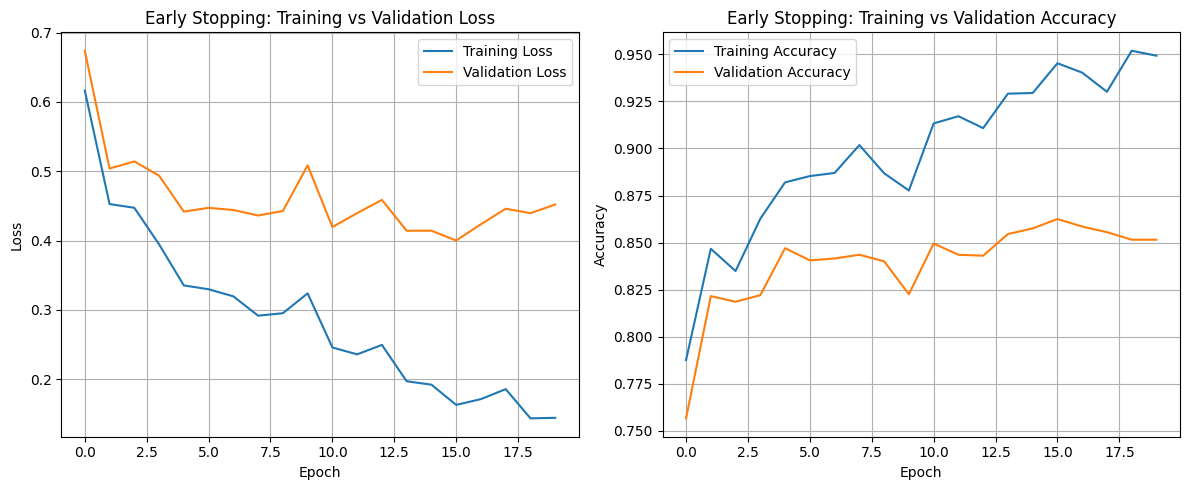

In [83]:
# #step 22 - Visualize early stopping results

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(early_stop_history["train_loss"], label="Training Loss")
plt.plot(early_stop_history["val_loss"], label="Validation Loss")
plt.title("Early Stopping: Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(early_stop_history["train_accuracy"], label="Training Accuracy")
plt.plot(early_stop_history["val_accuracy"], label="Validation Accuracy")
plt.title("Early Stopping: Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [84]:
# #step 22 - Identify the best early stopping epoch

best_epoch = np.argmin(early_stop_history["val_loss"])

print("Best epoch:", best_epoch + 1)
print("Best validation loss:",
      early_stop_history["val_loss"][best_epoch])

print("Validation accuracy at best epoch:",
      early_stop_history["val_accuracy"][best_epoch] * 100, "%")

print("Total epochs completed:",
      len(early_stop_history["val_loss"]))

Best epoch: 16
Best validation loss: 0.4001322678612321
Validation accuracy at best epoch: 86.25 %
Total epochs completed: 20


### Observation – Early Stopping

Early stopping was implemented by monitoring validation loss with a patience value of 4 epochs.

The model achieved its lowest validation loss of 0.4001 at epoch 16, with a validation accuracy of 86.25%. Since validation loss did not improve for four consecutive epochs, training stopped at epoch 20 instead of continuing to the maximum of 30 epochs.

The model parameters from epoch 16 were restored.

This experiment demonstrates how early stopping prevents unnecessary training after validation performance stops improving and helps retain the model with the best validation performance.

In [85]:
# #step 22 - Evaluate restored early stopping model

def evaluate_model(model, X, y, batch_size=128):

    probabilities = []

    for start in range(0, len(X), batch_size):
        X_batch = X[start:start + batch_size]
        probabilities.append(model.forward(X_batch))

    probabilities = np.vstack(probabilities)

    accuracy = np.mean(
        np.argmax(probabilities, axis=1) == y
    )

    loss = -np.mean(
        np.log(np.clip(
            probabilities[np.arange(len(y)), y],
            1e-12, 1.0
        ))
    )

    return loss, accuracy


restored_loss, restored_accuracy = evaluate_model(
    early_stop_model, X_val, y_val
)

print("Restored model validation loss:", restored_loss)
print("Restored model validation accuracy:",
      restored_accuracy * 100, "%")

Restored model validation loss: 0.4001322678612321
Restored model validation accuracy: 86.25 %


In [87]:
# #step 23.1 - Verify the restored early stopping model

def evaluate_model(model, X, y, batch_size=128):
    probabilities = []

    for start in range(0, len(X), batch_size):
        X_batch = X[start:start + batch_size]
        probabilities.append(model.forward(X_batch))

    probabilities = np.vstack(probabilities)

    accuracy = np.mean(np.argmax(probabilities, axis=1) == y)

    loss = -np.mean(
        np.log(
            np.clip(
                probabilities[np.arange(len(y)), y],
                1e-12,
                1.0
            )
        )
    )

    return loss, accuracy


restored_loss, restored_accuracy = evaluate_model(
    early_stop_model,
    X_val,
    y_val
)

print("Restored Model Validation Loss:", restored_loss)
print("Restored Model Validation Accuracy:", restored_accuracy * 100, "%")

Restored Model Validation Loss: 0.4001322678612321
Restored Model Validation Accuracy: 86.25 %


Create the Plain MLP baseline
We'll use the same architecture for both models so the comparison is more meaningful:
- Input: 784 neurons
- Hidden layers: 256 → 128 → 128
- Output: 10 classes

In [95]:
# #step 24.1 - Create a plain MLP for comparison

class PlainComparisonMLP:

    def __init__(self, input_size=784, hidden1=256,
                 hidden2=128, hidden3=128, output_size=10):

        self.params = {
            "W1": np.random.randn(input_size, hidden1) * np.sqrt(2 / input_size),
            "b1": np.zeros((1, hidden1)),

            "W2": np.random.randn(hidden1, hidden2) * np.sqrt(2 / hidden1),
            "b2": np.zeros((1, hidden2)),

            "W3": np.random.randn(hidden2, hidden3) * np.sqrt(2 / hidden2),
            "b3": np.zeros((1, hidden3)),

            "W4": np.random.randn(hidden3, output_size) * np.sqrt(2 / hidden3),
            "b4": np.zeros((1, output_size))
        }

    def relu(self, x):
        return np.maximum(0, x)

    def forward(self, X):

        p = self.params

        self.z1 = X @ p["W1"] + p["b1"]
        self.a1 = self.relu(self.z1)

        self.z2 = self.a1 @ p["W2"] + p["b2"]
        self.a2 = self.relu(self.z2)

        self.z3 = self.a2 @ p["W3"] + p["b3"]
        self.a3 = self.relu(self.z3)

        self.z4 = self.a3 @ p["W4"] + p["b4"]

        exp_scores = np.exp(self.z4 - np.max(self.z4, axis=1, keepdims=True))
        self.probs = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

        return self.probs

     # #step 24.2 - Implement backpropagation for Plain MLP

    def backward(self, X, y):

        p = self.params
        m = X.shape[0]

        # Output layer gradients
        dz4 = self.probs.copy()
        dz4[np.arange(m), y] -= 1
        dz4 /= m

        dW4 = self.a3.T @ dz4
        db4 = np.sum(dz4, axis=0, keepdims=True)

        # Third hidden layer gradients
        da3 = dz4 @ p["W4"].T
        dz3 = da3 * (self.z3 > 0)

        dW3 = self.a2.T @ dz3
        db3 = np.sum(dz3, axis=0, keepdims=True)

        # Second hidden layer gradients
        da2 = dz3 @ p["W3"].T
        dz2 = da2 * (self.z2 > 0)

        dW2 = self.a1.T @ dz2
        db2 = np.sum(dz2, axis=0, keepdims=True)

        # First hidden layer gradients
        da1 = dz2 @ p["W2"].T
        dz1 = da1 * (self.z1 > 0)

        dW1 = X.T @ dz1
        db1 = np.sum(dz1, axis=0, keepdims=True)

        return {
            "W1": dW1, "b1": db1,
            "W2": dW2, "b2": db2,
            "W3": dW3, "b3": db3,
            "W4": dW4, "b4": db4
        }

In [97]:
# #step 24.3 - Test Plain MLP

np.random.seed(42)

plain_model = PlainComparisonMLP()

# Test with a small batch of 10 images
X_sample = X_train[:10]
y_sample = y_train[:10]

# Forward propagation
predictions = plain_model.forward(X_sample)

# Backward propagation
gradients = plain_model.backward(X_sample, y_sample)

print("Prediction shape:", predictions.shape)
print("Gradient shapes:")

for name, gradient in gradients.items():
    print(name, gradient.shape)

Prediction shape: (10, 10)
Gradient shapes:
W1 (784, 256)
b1 (1, 256)
W2 (256, 128)
b2 (1, 128)
W3 (128, 128)
b3 (1, 128)
W4 (128, 10)
b4 (1, 10)


In [104]:
# #step 25.1 - Create Residual MLP

class ResidualMLP(PlainComparisonMLP):

    def forward(self, X):

        p = self.params

        self.z1 = X @ p["W1"] + p["b1"]
        self.a1 = self.relu(self.z1)

        self.z2 = self.a1 @ p["W2"] + p["b2"]
        self.a2 = self.relu(self.z2)

        # Residual block
        self.z3 = self.a2 @ p["W3"] + p["b3"]
        self.a3 = self.relu(self.z3)

        # Shortcut connection
        self.h = self.a2 + self.a3

        # Output layer
        self.z4 = self.h @ p["W4"] + p["b4"]

        exp_scores = np.exp(
            self.z4 - np.max(self.z4, axis=1, keepdims=True)
        )

        self.probs = exp_scores / np.sum(
            exp_scores, axis=1, keepdims=True
        )

        return self.probs
    # #step 25.2 - Implement backpropagation for Residual MLP

    def backward(self, X, y):

        p = self.params
        m = X.shape[0]

        # Output layer gradients
        dz4 = self.probs.copy()
        dz4[np.arange(m), y] -= 1
        dz4 /= m

        dW4 = self.h.T @ dz4
        db4 = np.sum(dz4, axis=0, keepdims=True)

        # Gradient flowing back from output
        dh = dz4 @ p["W4"].T

        # Residual block gradients
        # Gradient passes through the shortcut and transformed paths
        dz3 = dh * (self.z3 > 0)

        dW3 = self.a2.T @ dz3
        db3 = np.sum(dz3, axis=0, keepdims=True)

        # Add gradients from both paths
        da2 = dh + dz3 @ p["W3"].T

        # Second hidden layer gradients
        dz2 = da2 * (self.z2 > 0)

        dW2 = self.a1.T @ dz2
        db2 = np.sum(dz2, axis=0, keepdims=True)

        # First hidden layer gradients
        da1 = dz2 @ p["W2"].T
        dz1 = da1 * (self.z1 > 0)

        dW1 = X.T @ dz1
        db1 = np.sum(dz1, axis=0, keepdims=True)

        return {
            "W1": dW1, "b1": db1,
            "W2": dW2, "b2": db2,
            "W3": dW3, "b3": db3,
            "W4": dW4, "b4": db4
        }

In [105]:
# #step 25.3 - Test Residual MLP

np.random.seed(42)

residual_model = ResidualMLP()

# Use the same sample images and labels
predictions = residual_model.forward(X_sample)

gradients = residual_model.backward(X_sample, y_sample)

print("Prediction shape:", predictions.shape)

print("\nGradient shapes:")

for name, gradient in gradients.items():
    print(name, gradient.shape)

Prediction shape: (10, 10)

Gradient shapes:
W1 (784, 256)
b1 (1, 256)
W2 (256, 128)
b2 (1, 128)
W3 (128, 128)
b3 (1, 128)
W4 (128, 10)
b4 (1, 10)


We'll train both models using:
- Optimizer: Adam
- Learning rate: 0.001
- Epochs: 20
- Batch size: 128
- Training data: 6,000 images
- Validation data: 2,000 images

In [111]:
# #step 26.1 - Training function for Plain and Residual MLP

def train_comparison_model(model, X_train_data, y_train_data,
                           X_val_data, y_val_data,
                           epochs=20, batch_size=128):

    optimizer = Optimizer(method="adam", learning_rate=0.001)

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    for epoch in range(epochs):

        indices = np.random.permutation(len(X_train_data))
        X_shuffled = X_train_data[indices]
        y_shuffled = y_train_data[indices]

        for start in range(0, len(X_train_data), batch_size):

            X_batch = X_shuffled[start:start + batch_size]
            y_batch = y_shuffled[start:start + batch_size]

            model.forward(X_batch)
            gradients = model.backward(X_batch, y_batch)

            optimizer.update(model.params, gradients)

        # Evaluate training and validation data
        train_loss, train_acc = evaluate_model(
            model, X_train_data, y_train_data
        )

        val_loss, val_acc = evaluate_model(
            model, X_val_data, y_val_data
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Accuracy: {train_acc*100:.2f}% | "
            f"Validation Accuracy: {val_acc*100:.2f}%"
        )

    return history

In [112]:
# #step 26.2 - Train Plain MLP

np.random.seed(42)

plain_model = PlainComparisonMLP()

plain_history = train_comparison_model(
    plain_model,
    X_train_overfit,
    y_train_overfit,
    X_val,
    y_val,
    epochs=20,
    batch_size=128
)

print("\nPlain MLP Training Completed!")

Epoch 1/20 | Train Accuracy: 80.82% | Validation Accuracy: 79.05%
Epoch 2/20 | Train Accuracy: 83.85% | Validation Accuracy: 80.30%
Epoch 3/20 | Train Accuracy: 86.15% | Validation Accuracy: 82.70%
Epoch 4/20 | Train Accuracy: 87.48% | Validation Accuracy: 83.60%
Epoch 5/20 | Train Accuracy: 88.33% | Validation Accuracy: 83.95%
Epoch 6/20 | Train Accuracy: 87.47% | Validation Accuracy: 83.95%
Epoch 7/20 | Train Accuracy: 90.33% | Validation Accuracy: 84.75%
Epoch 8/20 | Train Accuracy: 90.77% | Validation Accuracy: 85.30%
Epoch 9/20 | Train Accuracy: 91.42% | Validation Accuracy: 85.35%
Epoch 10/20 | Train Accuracy: 91.57% | Validation Accuracy: 86.40%
Epoch 11/20 | Train Accuracy: 91.62% | Validation Accuracy: 85.15%
Epoch 12/20 | Train Accuracy: 92.60% | Validation Accuracy: 85.75%
Epoch 13/20 | Train Accuracy: 90.67% | Validation Accuracy: 83.60%
Epoch 14/20 | Train Accuracy: 93.33% | Validation Accuracy: 85.30%
Epoch 15/20 | Train Accuracy: 93.00% | Validation Accuracy: 85.25%
Epoc

In [113]:
# #step 26.3 - Train Residual MLP

np.random.seed(42)

residual_model = ResidualMLP()

residual_history = train_comparison_model(
    residual_model,
    X_train_overfit,
    y_train_overfit,
    X_val,
    y_val,
    epochs=20,
    batch_size=128
)

print("\nResidual MLP Training Completed!")

Epoch 1/20 | Train Accuracy: 80.68% | Validation Accuracy: 78.65%
Epoch 2/20 | Train Accuracy: 84.43% | Validation Accuracy: 80.90%
Epoch 3/20 | Train Accuracy: 85.58% | Validation Accuracy: 82.30%
Epoch 4/20 | Train Accuracy: 87.32% | Validation Accuracy: 83.15%
Epoch 5/20 | Train Accuracy: 89.20% | Validation Accuracy: 85.05%
Epoch 6/20 | Train Accuracy: 87.67% | Validation Accuracy: 83.55%
Epoch 7/20 | Train Accuracy: 89.83% | Validation Accuracy: 84.60%
Epoch 8/20 | Train Accuracy: 91.35% | Validation Accuracy: 85.25%
Epoch 9/20 | Train Accuracy: 92.23% | Validation Accuracy: 86.15%
Epoch 10/20 | Train Accuracy: 91.57% | Validation Accuracy: 84.85%
Epoch 11/20 | Train Accuracy: 92.15% | Validation Accuracy: 85.85%
Epoch 12/20 | Train Accuracy: 92.72% | Validation Accuracy: 84.80%
Epoch 13/20 | Train Accuracy: 92.82% | Validation Accuracy: 85.10%
Epoch 14/20 | Train Accuracy: 93.53% | Validation Accuracy: 85.00%
Epoch 15/20 | Train Accuracy: 94.08% | Validation Accuracy: 84.95%
Epoc

In [117]:
# #step 26.4 - Compare Plain MLP and Residual MLP

import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Plain MLP", "Residual MLP"],

    "Final Training Accuracy (%)": [
        plain_history["train_accuracy"][-1] * 100,
        residual_history["train_accuracy"][-1] * 100
    ],

    "Final Validation Accuracy (%)": [
        plain_history["val_accuracy"][-1] * 100,
        residual_history["val_accuracy"][-1] * 100
    ],

    "Final Training Loss": [
        plain_history["train_loss"][-1],
        residual_history["train_loss"][-1]
    ],

    "Final Validation Loss": [
        plain_history["val_loss"][-1],
        residual_history["val_loss"][-1]
    ]
})

comparison.round(4)

,Model,Final Training Accuracy (%),Final Validation Accuracy (%),Final Training Loss,Final Validation Loss
0,Plain MLP,95.4500,86.5,0.1309,0.4300
1,Residual MLP,95.1833,85.2,0.1354,0.4826


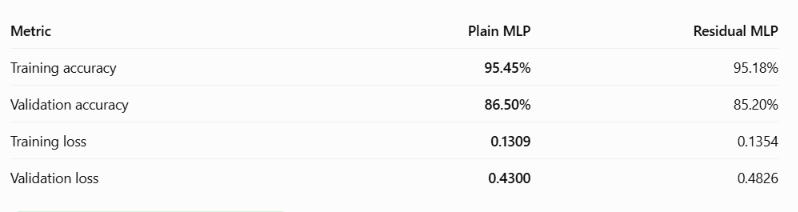

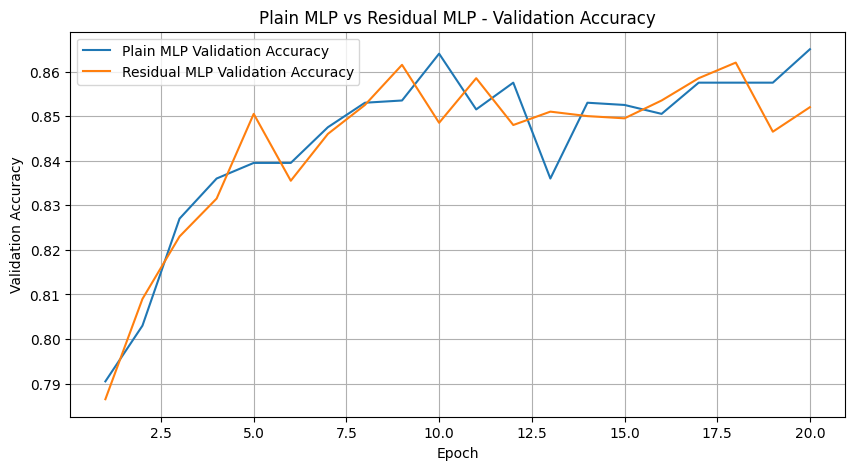

In [118]:
# #step 26.5 - Compare accuracy curves

import matplotlib.pyplot as plt

epochs_range = range(1, 21)

plt.figure(figsize=(10, 5))

plt.plot(epochs_range,
         plain_history["val_accuracy"],
         label="Plain MLP Validation Accuracy")

plt.plot(epochs_range,
         residual_history["val_accuracy"],
         label="Residual MLP Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Plain MLP vs Residual MLP - Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

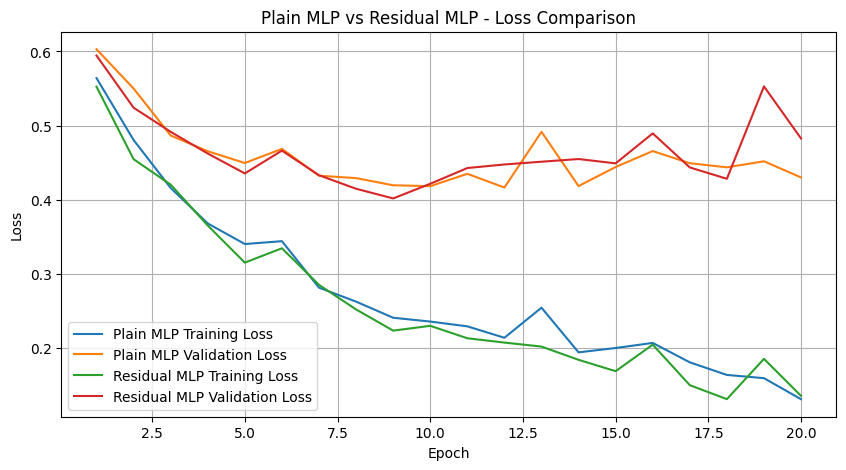

In [119]:
# #step 26.6 - Compare loss curves

plt.figure(figsize=(10, 5))

plt.plot(epochs_range,
         plain_history["train_loss"],
         label="Plain MLP Training Loss")

plt.plot(epochs_range,
         plain_history["val_loss"],
         label="Plain MLP Validation Loss")

plt.plot(epochs_range,
         residual_history["train_loss"],
         label="Residual MLP Training Loss")

plt.plot(epochs_range,
         residual_history["val_loss"],
         label="Residual MLP Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Plain MLP vs Residual MLP - Loss Comparison")
plt.legend()
plt.grid(True)
plt.show()

### Observation – Plain MLP vs Residual MLP

Both Plain MLP and Residual MLP were trained using the Adam optimizer with a learning rate of 0.001 for 20 epochs on the Fashion-MNIST dataset.

The Plain MLP achieved a final training accuracy of 95.45% and validation accuracy of 86.50%. The Residual MLP achieved 95.18% training accuracy and 85.20% validation accuracy.

The loss curves show that both models learned the training data effectively. However, their validation losses fluctuated while training losses continued to decrease, indicating overfitting.

The Plain MLP achieved slightly better validation performance. In this experiment, residual connections did not provide a noticeable improvement in generalization.

**Conclusion:** For this network architecture and dataset, the Plain MLP performed slightly better than the Residual MLP.

In [120]:
# #step 27.1 - Overall Optimizer and Learning Rate Comparison

optimizer_results = pd.DataFrame({
    "Optimizer": ["SGD", "Momentum", "RMSProp", "Adam"],
    "Training Accuracy (%)": [61.46, 61.05, 85.88, 89.18],
    "Test Accuracy (%)": [60.40, 60.50, 82.35, 85.55],
    "Training Loss": [1.5222, 1.5354, 0.3721, 0.3130]
})

schedule_results = pd.DataFrame({
    "Schedule": ["Constant", "Step", "Exponential"],
    "Training Accuracy (%)": [89.225, 89.10, 89.80],
    "Test Accuracy (%)": [85.75, 86.30, 86.30],
    "Training Loss": [0.3123, 0.3266, 0.3088]
})

print("OPTIMIZER COMPARISON")
display(optimizer_results)

print("\nLEARNING RATE SCHEDULE COMPARISON")
display(schedule_results)

OPTIMIZER COMPARISON


,Optimizer,Training Accuracy (%),Test Accuracy (%),Training Loss
0,SGD,61.46,60.40,1.5222
1,Momentum,61.05,60.50,1.5354
2,RMSProp,85.88,82.35,0.3721
3,Adam,89.18,85.55,0.3130



LEARNING RATE SCHEDULE COMPARISON


,Schedule,Training Accuracy (%),Test Accuracy (%),Training Loss
0,Constant,89.225,85.75,0.3123
1,Step,89.100,86.30,0.3266
2,Exponential,89.800,86.30,0.3088


In [122]:
# #step 27.2 - Compare Regularization Methods

regularization_results = pd.DataFrame({
    "Method": [
        "Baseline",
        "Dropout",
        "L2 Regularization",
        "Data Augmentation",
        "Early Stopping"
    ],

    "Final Training Accuracy (%)": [
        94.93, 91.75, 93.22, 82.42, 94.93
    ],

    "Final Validation Accuracy (%)": [
        85.15, 85.45, 85.15, 79.70, 85.15
    ],

    "Best Validation Accuracy (%)": [
        85.15, np.nan, 86.75, 81.70, 86.25
    ]
})

display(regularization_results.round(2))

,Method,Final Training Accuracy (%),Final Validation Accuracy (%),Best Validation Accuracy (%)
0,Baseline,94.93,85.15,85.15
1,Dropout,91.75,85.45,NaN
2,L2 Regularization,93.22,85.15,86.75
3,Data Augmentation,82.42,79.70,81.70
4,Early Stopping,94.93,85.15,86.25


In [124]:
# #step 27.3 - Compare Plain MLP and Residual MLP

final_model_comparison = pd.DataFrame({
    "Model": ["Plain MLP", "Residual MLP"],

    "Training Accuracy (%)": [
        plain_history["train_accuracy"][-1] * 100,
        residual_history["train_accuracy"][-1] * 100
    ],

    "Validation Accuracy (%)": [
        plain_history["val_accuracy"][-1] * 100,
        residual_history["val_accuracy"][-1] * 100
    ],

    "Training Loss": [
        plain_history["train_loss"][-1],
        residual_history["train_loss"][-1]
    ],

    "Validation Loss": [
        plain_history["val_loss"][-1],
        residual_history["val_loss"][-1]
    ]
})

display(final_model_comparison.round(4))

,Model,Training Accuracy (%),Validation Accuracy (%),Training Loss,Validation Loss
0,Plain MLP,95.4500,86.5,0.1309,0.4300
1,Residual MLP,95.1833,85.2,0.1354,0.4826


# Overall Conclusion

In this program, different optimization techniques, learning-rate scheduling strategies and regularization methods were implemented and evaluated using a small subset of the Fashion-MNIST dataset.

The experiments produced the following observations:

1. **Gradient Descent:** Batch, Stochastic and Mini-batch Gradient Descent all reduced the prediction error. Their convergence behaviour differed across the experiments.

2. **Optimizer Comparison:** Adam achieved the highest test accuracy of 85.55%, followed by RMSProp at 82.35%.

3. **Learning-Rate Scheduling:** Step and Exponential scheduling achieved the highest test accuracy of 86.30%, slightly outperforming the constant learning rate.

4. **Regularization:** Dropout reduced the training-validation accuracy gap. L2 regularization achieved the best validation accuracy of 86.75% at epoch 18. Data augmentation reduced the gap but also reduced overall accuracy in this experiment.

5. **Early Stopping:** Early stopping selected the best model at epoch 16, achieving 86.25% validation accuracy and preventing unnecessary additional training.

6. **Plain MLP vs Residual MLP:** The Plain MLP achieved 86.50% validation accuracy, slightly outperforming the Residual MLP at 85.20%.

Overall, the experiments demonstrate how optimizer selection, learning-rate scheduling and regularization influence neural-network training and generalization. The results also show that more complex architectures and regularization techniques do not necessarily improve performance in every experiment.